# What does it actually cost to hire a person in Silicon Valley?

**Geography:** San Francisco Bay Area · **Tax year:** 2026 · **Compiled:** 26 October 2026 · **Currency:** USD

A base salary is an invoice line. The *cost of a person* is something else: statutory taxes that
don't move with the headline number, a benefits bill that is almost flat in dollars and therefore
regressive as a percentage, an overhead stack that nobody puts in the offer letter, and equity
whose accounting cost and human value are two different quantities that diverge badly.

This notebook builds that number from the bottom up, from cited sources, with every assumption
exposed as a parameter you can change.

### The questions it answers

| # | Question | Section |
|---|---|---|
| 1 | What does the Bay Area market actually pay? | [§2](#s2) |
| 2 | What do employer payroll taxes really cost — and why don't they scale? | [§3](#s3) |
| 3 | What does each benefit cost, and which ones are worth the money? | [§4](#s4) |
| 4 | What's in the overhead stack nobody budgets for? | [§5](#s5) |
| 5 | What is the fully-loaded multiple on base salary? | [§6](#s6) |
| 6 | **Interactive:** pick a salary and a benefits package, see the cost | [§7](#s7) |
| 7 | What does equity cost the company vs. what does the employee get? | [§8](#s8) |
| 8 | **How often do stock options actually vest?** (Monte Carlo) | [§9](#s9) |
| 9 | **How wrong could all of this be?** (uncertainty + sensitivity) | [§10](#s10) |
| 10 | How much revenue does this person have to generate? | [§11](#s11) |
| 11 | What does it cost when they leave? | [§12](#s12) |

### How to run it

```bash
python3 -m venv .venv && ./.venv/bin/pip install numpy pandas matplotlib scipy ipywidgets jupyterlab
./.venv/bin/jupyter lab cost_of_a_person.ipynb
```

Run top to bottom. The interactive controls in §7 and §9 need a live kernel; every section also
renders a static default so the notebook reads correctly as a document.

## Method, and what this model refuses to do

**Six tiers, deliberately kept apart.** Most "true cost of an employee" calculators produce one
scary multiple by mixing incremental cash costs with accounting allocations. They are not the same
thing and they answer different questions, so this model keeps them separate and lets you decide
which to add up:

| Tier | What it is | Cash? | Incremental to one more hire? |
|---|---|---|---|
| 1 · Direct cash comp | base + cash bonus | yes | yes |
| 2 · Statutory | employer payroll taxes, workers' comp | yes | yes |
| 3 · Benefits | health, retirement, leave, perks | yes | mostly |
| 4 · Operating overhead | recruiting, space, tools, devices, cloud | yes | partly — space is lumpy |
| 5 · Equity | GAAP stock-based compensation expense | **no** | yes |
| 6 · Allocated org overhead | share of management, HR, finance, legal | yes | **no** — an allocation |

**Three double-counts this model deliberately avoids.**

1. *Paid leave.* BLS counts paid time off as a benefit worth ~9% of total compensation. For a
   salaried engineer, that time is already inside the salary — you pay the same $241k whether they
   take 10 days or 25. Charging PTO again as a benefit inflates the answer. It is modelled here as
   an effect on *productive hours* (and, in California, as an accrual liability), not as extra dollars.
2. *Supplemental pay.* BLS's "supplemental pay" is bonuses — already Tier 1 here.
3. *CA SDI.* State Disability Insurance is employee-paid in California. It appears in the model
   only so it can be explicitly excluded; it shows up as an employer cost in a surprising number of
   published calculators.

**Calibration.** The bottom-up model is checked against the BLS Employer Costs for Employee
Compensation release — the only authoritative, nationally representative measurement of this
quantity — in §6. If the model disagrees with BLS by more than the Bay Area premium can explain,
the model is wrong.

**Source discipline.** Every input lives in `data/sources.json` with a URL, an as-of date and a
confidence tier: **A** = primary filing or government release, **B** = large private dataset from
its owner, **C** = secondary reporting or practitioner benchmark. §10 propagates that uncertainty
through to the final number rather than hiding it behind a point estimate.

In [1]:
# --- Setup -------------------------------------------------------------------
import json, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Rectangle

RNG = np.random.default_rng(20261026)   # fixed seed: every figure here is reproducible

# --- Chart design system -----------------------------------------------------
# Categorical hues are assigned in FIXED ORDER, never cycled. Validated for
# colour-vision-deficiency separation on adjacent pairs; forms that compare all
# pairs at once (scatter) use at most the first three slots.
SURFACE   = "#fcfcfb"
INK       = "#0b0b0b"   # primary text
INK_2     = "#52514e"   # secondary text
INK_3     = "#8a8880"   # muted text
GRID      = "#e6e5e0"
SERIES    = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
             "#008300", "#6250d6", "#e34948"]
STATUS    = {"good": "#0ca30c", "warning": "#fab219",
             "serious": "#ec835a", "critical": "#d03b3b"}
BLUE_RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
             "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 120, "savefig.dpi": 120,
    "font.size": 10.5,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": GRID,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "axes.titlesize": 12.5, "axes.labelsize": 10,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.alpha": 1.0,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": True,
    "lines.linewidth": 2.0, "lines.solid_capstyle": "round",
    "legend.frameon": False, "legend.fontsize": 9.5,
    "figure.autolayout": False,
    # Dollar signs are everywhere in this notebook; keep matplotlib from reading
    # them as LaTeX math delimiters.
    "text.parse_math": False,
})

def money(x, _pos=None):
    "Axis/label formatter: compact dollars."
    x = float(x)
    s = "-" if x < 0 else ""
    x = abs(x)
    if x >= 1_000_000: return f"{s}${x/1_000_000:,.2f}M"
    if x >= 1_000:     return f"{s}${x/1_000:,.0f}k"
    return f"{s}${x:,.0f}"

MONEY = FuncFormatter(money)

def dollars(x):
    "Exact dollars, for prose and tables where rounding to $k would mislead."
    return f"${x:,.0f}"

def frame(ax, title=None, subtitle=None, xlabel=None, ylabel=None,
          ygrid=True, xgrid=False, money_y=False, money_x=False):
    "Apply the house style to an axes: recessive grid, titles, formatters."
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=ygrid)
    ax.grid(axis="x", visible=xgrid)
    if title:
        ax.set_title(title, loc="left", color=INK, pad=20 if subtitle else 10,
                     fontweight="bold")
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK_2,
                fontsize=9.5, va="bottom", ha="left")
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    if money_y: ax.yaxis.set_major_formatter(MONEY)
    if money_x: ax.xaxis.set_major_formatter(MONEY)
    ax.tick_params(length=0)
    return ax

def source_note(fig, text):
    "Attribution line under a figure."
    fig.text(0.005, -0.02, text, color=INK_3, fontsize=8.3, ha="left", va="top")

print(f"numpy {np.__version__} · pandas {pd.__version__} · matplotlib {mpl.__version__}")

numpy 2.5.4 · pandas 3.1.0 · matplotlib 3.11.2


<a id="s1"></a>
## 1 · The inputs, and how much to trust them

Every number below is declared once, in `data/sources.json`, with a URL, an as-of date and a
confidence tier. Nothing in this notebook is a number I made up in a cell.

In [2]:
SRC = json.loads(Path("data/sources.json").read_text())

rows = [
    ("Bay Area SWE total comp (median)", "$280,000", "B", "levels.fyi, n=12,061", "2026-10-27"),
    ("Bay Area SWE total comp (p25 / p75 / p90)", "$206k / $384k / $512k", "B", "levels.fyi", "2026-10-27"),
    ("Google Bay Area SWE by level L3-L6", "$231k - $684k", "B", "levels.fyi", "2026-10-26"),
    ("Employer benefit load, professional occupations", "30.8% of total comp", "A", "BLS ECEC June 2026, Table 4", "2026-06"),
    ("Social Security wage base", "$184,500 @ 6.2%", "A", "SSA / IRS 2026 COLA", "2026"),
    ("Medicare employer rate", "1.45%, uncapped", "A", "IRS", "2026"),
    ("CA SUI / ETT wage base", "$7,000", "B", "California EDD", "2026"),
    ("FUTA effective rate, California", "1.8% (2026 unsettled)", "B", "IRS credit-reduction notice", "2025"),
    ("Health premium, employer share", "$7,885 single / $20,143 family", "B", "KFF Employer Health Benefits Survey", "2025"),
    ("401(k) promised match", "4.7% of pay (mean)", "B", "Vanguard, How America Saves", "2025"),
    ("401(a)(17) compensation limit", "$360,000", "B", "IRS 2026 COLA", "2026"),
    ("SF office asking rent", "$70.31 - $72.68 /sqft gross", "B", "Savills / Cushman & Wakefield Q3 2026", "2026-Q3"),
    ("SF office vacancy", "29.3%", "B", "Cushman & Wakefield", "2026-Q3"),
    ("Cost per hire (non-exec mean)", "$5,475", "B", "SHRM 2025, n=2,371", "2025-10"),
    ("Agency fee, Bay Area engineering", "18-30% of base", "C", "Practitioner benchmark", "2026"),
    ("Alphabet FY2025 SBC / revenue", "$24.95B / $402.8B", "A", "SEC XBRL (10-K)", "2025-12-31"),
    ("Meta FY2025 SBC / revenue / headcount", "$20.43B / $200.97B / 78,865", "A", "SEC 10-K", "2025-12-31"),
    ("NVIDIA FY2026 SBC / revenue", "$6.39B / $215.9B", "A", "SEC XBRL (10-K)", "2026-01-25"),
    ("Median startup tenure", "2.0 years", "B", "Carta, 185k+ employees", "2018-2024"),
    ("50% departure probability reached at", "37 months", "B", "Carta", "2018-2024"),
    ("Seed -> Series A within 2 years (2022 cohort)", "~17%", "B", "Carta", "2024"),
    ("Share exercising vested options in 90 days", "~38%", "C", "Secondary, attributed to Pave", "2025"),
]
sources_df = pd.DataFrame(rows, columns=["Input", "Value", "Tier", "Source", "As of"])

def _tier_style(v):
    return {"A": "background-color:#e8f5e8;color:#0b0b0b",
            "B": "background-color:#fff8e6;color:#0b0b0b",
            "C": "background-color:#fdeceb;color:#0b0b0b"}.get(v, "")

display(sources_df.style
        .map(_tier_style, subset=["Tier"])
        .set_properties(**{"font-size": "11px"})
        .hide(axis="index"))

n_a = (sources_df.Tier == "A").sum(); n_b = (sources_df.Tier == "B").sum(); n_c = (sources_df.Tier == "C").sum()
print(f"\nTier A (primary): {n_a}   Tier B (owner-published dataset): {n_b}   Tier C (secondary/benchmark): {n_c}")
print("The Tier C rows are where the error bars in Section 10 come from.")

Input,Value,Tier,Source,As of
Bay Area SWE total comp (median),"$280,000",B,"levels.fyi, n=12,061",2026-10-27
Bay Area SWE total comp (p25 / p75 / p90),$206k / $384k / $512k,B,levels.fyi,2026-10-27
Google Bay Area SWE by level L3-L6,$231k - $684k,B,levels.fyi,2026-10-26
"Employer benefit load, professional occupations",30.8% of total comp,A,"BLS ECEC June 2026, Table 4",2026-06
Social Security wage base,"$184,500 @ 6.2%",A,SSA / IRS 2026 COLA,2026
Medicare employer rate,"1.45%, uncapped",A,IRS,2026
CA SUI / ETT wage base,"$7,000",B,California EDD,2026
"FUTA effective rate, California",1.8% (2026 unsettled),B,IRS credit-reduction notice,2025
"Health premium, employer share","$7,885 single / $20,143 family",B,KFF Employer Health Benefits Survey,2025
401(k) promised match,4.7% of pay (mean),B,"Vanguard, How America Saves",2025



Tier A (primary): 6   Tier B (owner-published dataset): 14   Tier C (secondary/benchmark): 2
The Tier C rows are where the error bars in Section 10 come from.


<a id="s2"></a>
## 2 · Q1 — What does the Bay Area market actually pay?

Two views, because they answer different questions.

**The market view** (levels.fyi, all SWE levels, Bay Area, n = 12,061): median **$280,000** total
comp, p25 $206k, p75 $384k, p90 $512k. The spread is the story — the 90th percentile is **2.5×**
the 25th for the same nominal job title. "What does an engineer cost?" has no single answer; it has
a distribution whose width is dominated by *level*, not by company.

**The level view** (Google, Bay Area, by level): useful because it is one of the few public
datasets that splits base / stock / bonus. The split matters enormously for cost, because only the
cash portion drives most payroll taxes and the 401(k) match, while the stock portion drives the
GAAP expense and nearly nothing else.

> **Caveat you should carry through the whole notebook.** levels.fyi is self-reported. It skews
> toward large public employers, toward people pleased enough with an offer to post it, and toward
> the kind of engineer who reads levels.fyi. Treat these medians as the upper half of the real
> market. §10 carries a downward adjustment band for exactly this.

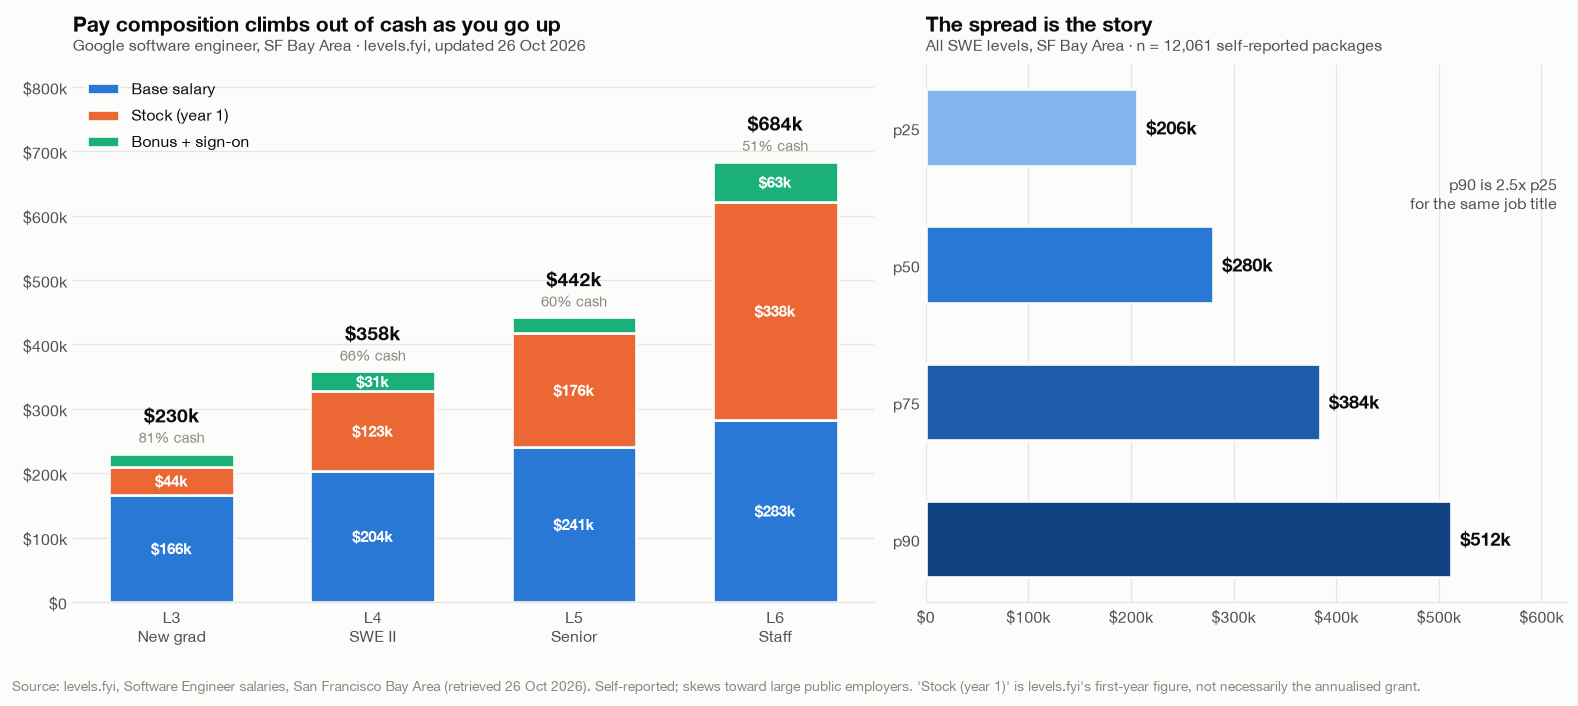

Cash share of total comp:  L3 81%   ->   L6 51%
Implication: the higher you hire, the less of the package touches payroll tax and 401(k) match,
and the more of it is a non-cash GAAP expense with a probabilistic value to the employee.


In [3]:
G = SRC["compensation"]["levels_fyi_google_bay_area_swe_by_level"]["value"]
levels = ["L3", "L4", "L5", "L6"]
titles = {"L3": "L3\nNew grad", "L4": "L4\nSWE II", "L5": "L5\nSenior", "L6": "L6\nStaff"}
base   = np.array([G[l]["base"] for l in levels], float)
stock  = np.array([G[l]["stock_year1"] for l in levels], float)
bonus  = np.array([G[l]["bonus"] for l in levels], float)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13.2, 5.6),
                               gridspec_kw={"width_ratios": [1.25, 1]})

# -- left: composition by level (stacked; 2px surface gap between segments)
x = np.arange(len(levels))
parts = [("Base salary", base, SERIES[0]),
         ("Stock (year 1)", stock, SERIES[1]),
         ("Bonus + sign-on", bonus, SERIES[2])]
bottom = np.zeros(len(levels))
for name, vals, c in parts:
    axL.bar(x, vals, 0.62, bottom=bottom, label=name, color=c,
            edgecolor=SURFACE, linewidth=1.6)
    for xi, (b, v) in enumerate(zip(bottom, vals)):
        if v > 28_000:
            axL.text(xi, b + v / 2, money(v), ha="center", va="center",
                     color="white", fontsize=9, fontweight="bold")
    bottom += vals

for xi, tot in enumerate(bottom):
    axL.text(xi, tot + 42_000, money(tot), ha="center", va="bottom",
             color=INK, fontsize=11.5, fontweight="bold")
    cash = (base[xi] + bonus[xi]) / tot
    axL.text(xi, tot + 12_000, f"{cash:.0%} cash", ha="center", va="bottom",
             color=INK_3, fontsize=8.8)

axL.set_xticks(x); axL.set_xticklabels([titles[l] for l in levels])
axL.set_ylim(0, bottom.max() * 1.22)
frame(axL, "Pay composition climbs out of cash as you go up",
      "Google software engineer, SF Bay Area · levels.fyi, updated 26 Oct 2026",
      money_y=True)
axL.legend(loc="upper left", ncols=1)

# -- right: the market distribution
P = SRC["compensation"]["levels_fyi_bay_area_swe_all_levels"]["value"]
pct = [25, 50, 75, 90]
vals = [P["p25"], P["p50"], P["p75"], P["p90"]]
cols = [BLUE_RAMP[3], BLUE_RAMP[7], BLUE_RAMP[9], BLUE_RAMP[11]]
bars = axR.barh([f"p{p}" for p in pct], vals, 0.56, color=cols,
                edgecolor=SURFACE, linewidth=1.6)
for b, v in zip(bars, vals):
    axR.text(v + 9_000, b.get_y() + b.get_height() / 2, money(v),
             va="center", ha="left", color=INK, fontsize=10.5, fontweight="bold")
axR.set_xlim(0, max(vals) * 1.22)
axR.invert_yaxis()
frame(axR, "The spread is the story",
      "All SWE levels, SF Bay Area · n = 12,061 self-reported packages",
      money_x=True, ygrid=False, xgrid=True)
axR.text(0.985, 0.76, f"p90 is {P['p90']/P['p25']:.1f}x p25\nfor the same job title",
         transform=axR.transAxes, ha="right", va="center", color=INK_2, fontsize=9.5)

fig.tight_layout()
source_note(fig, "Source: levels.fyi, Software Engineer salaries, San Francisco Bay Area (retrieved 26 Oct 2026). "
                 "Self-reported; skews toward large public employers. 'Stock (year 1)' is levels.fyi's first-year figure, "
                 "not necessarily the annualised grant.")
plt.show()

print(f"Cash share of total comp:  L3 {(base[0]+bonus[0])/bottom[0]:.0%}   ->   L6 {(base[3]+bonus[3])/bottom[3]:.0%}")
print("Implication: the higher you hire, the less of the package touches payroll tax and 401(k) match,")
print("and the more of it is a non-cash GAAP expense with a probabilistic value to the employee.")

<a id="s3"></a>
## 3 · Q2 — Employer payroll taxes, and why they don't scale

This is the most misunderstood line in the stack. The intuition is "payroll tax is ~7.65%, so a
$241k engineer costs $18k in tax." That is wrong in both directions, and the errors don't cancel.

**Why it's less than you think.** Three of the five employer taxes are capped, and two of them are
capped absurdly low:

- Social Security stops at **$184,500** of wages (2026). Above that, the 6.2% simply ends.
- California SUI and ETT apply to the first **$7,000** — *ever*, per employee per year. At the
  3.4% new-employer rate that is **$238**, flat, for a $150k engineer and a $600k one alike.
- FUTA is the first $7,000 too.

So employer payroll tax is **steeply regressive**. It is ~7.4% of a $100k salary and under 5% of a
$400k one.

**Why it's more than you think.** RSUs are W-2 wages at vest. The employer owes FICA on them. Base
salary has usually blown through the Social Security cap already, so the marginal rate on equity is
"only" Medicare's 1.45% — but on a $176k annual grant that is **$2,552 a year of cash tax on a
non-cash benefit**, which almost nobody budgets.

**And one thing that is not a cost at all.** California SDI is employee-paid. It is ~1.3% of
uncapped wages in 2026 and it appears as an employer cost in a remarkable number of published
calculators. It is zero to you.

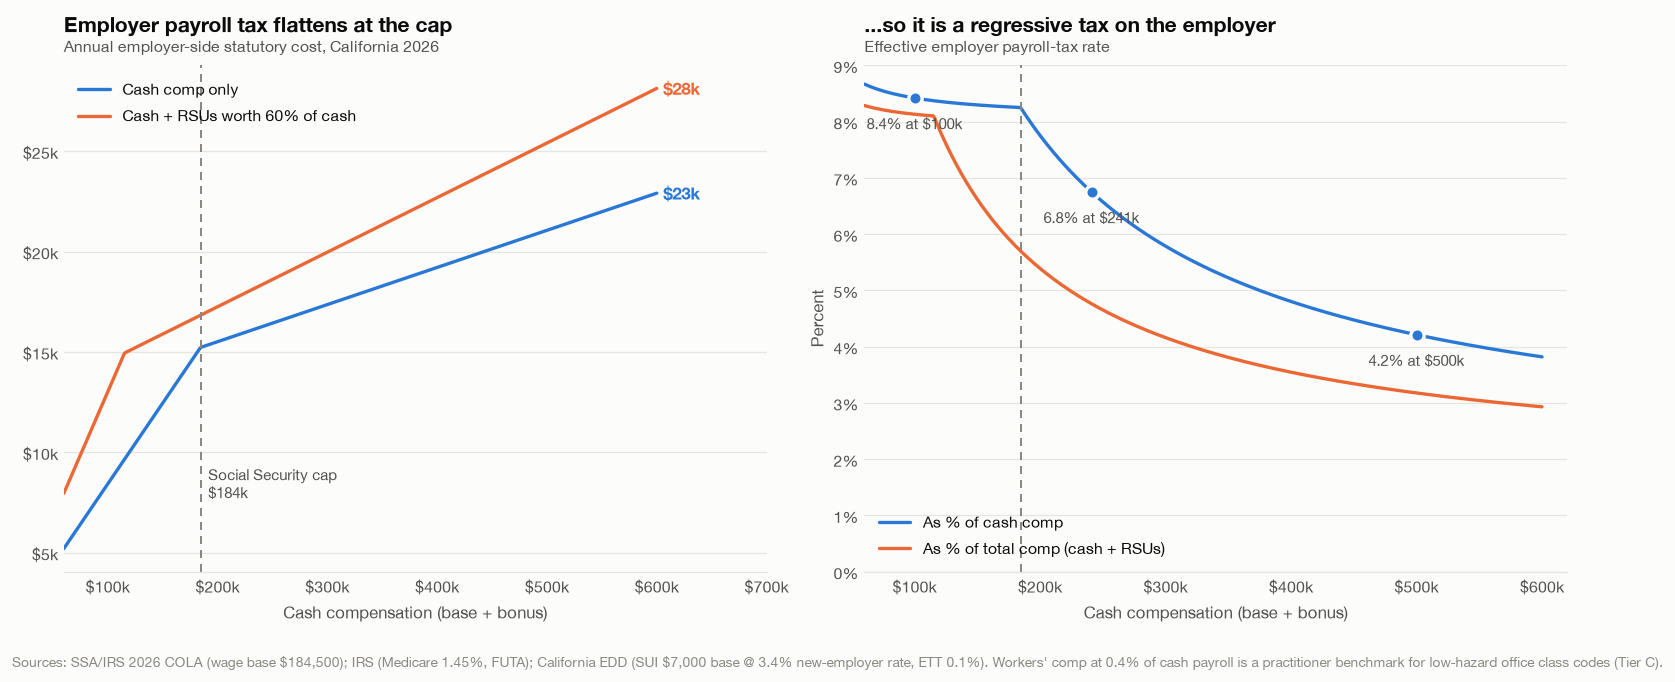

,$100k cash,$241k cash,$500k cash
"Social Security (6.2%, capped)",$10k,$11k,$11k
"Medicare (1.45%, uncapped)",$2k,$6k,$12k
FUTA (CA credit reduction),$126,$126,$126
CA SUI,$238,$238,$238
CA ETT,$7,$7,$7
Workers' compensation,$400,$964,$2k
TOTAL,$13k,$18k,$25k



Note the two flat lines: CA SUI is $238 and CA ETT is $7 at every salary on this table.
Note also that Medicare is the only line that keeps growing — it is what makes equity cost cash.


In [4]:
TX = SRC["payroll_taxes_2026"]

TAX_DEFAULTS = dict(
    ss_rate   = TX["social_security"]["employer_rate"],      # 6.2%
    ss_base   = TX["social_security"]["wage_base"],          # $184,500
    med_rate  = TX["medicare"]["employer_rate"],             # 1.45%, uncapped
    futa_rate = TX["futa"]["california_effective_rate_2025"],# 1.8% CA credit-reduction
    sui_rate  = TX["ca_sui"]["new_employer_rate"],           # 3.4% new employer
    ett_rate  = TX["ca_ett"]["rate"],                        # 0.1%
    ui_base   = TX["ca_sui"]["wage_base"],                   # $7,000
    wc_rate   = TX["workers_compensation"]["default_rate"],  # 0.4% of cash payroll
)

def employer_payroll_taxes(cash_wages, equity_vest_value=0.0, **kw):
    """Employer-side statutory cost. `cash_wages` = base + cash bonus.

    RSUs vesting are W-2 wages, so FICA applies to them too; they are NOT subject
    to the $7,000-base state taxes in any meaningful way (the base is exhausted by
    salary in week one) and are excluded from the workers' comp payroll base here.
    """
    p = {**TAX_DEFAULTS, **kw}
    fica_wages = cash_wages + equity_vest_value
    return {
        "Social Security (6.2%, capped)": p["ss_rate"] * min(fica_wages, p["ss_base"]),
        "Medicare (1.45%, uncapped)":     p["med_rate"] * fica_wages,
        "FUTA (CA credit reduction)":     p["futa_rate"] * min(fica_wages, p["ui_base"]),
        "CA SUI":                         p["sui_rate"] * min(fica_wages, p["ui_base"]),
        "CA ETT":                         p["ett_rate"] * min(fica_wages, p["ui_base"]),
        "Workers' compensation":          p["wc_rate"] * cash_wages,
    }

# --- the regressivity curve
sal = np.linspace(60_000, 600_000, 541)
tot_nostock = np.array([sum(employer_payroll_taxes(s).values()) for s in sal])
tot_stock   = np.array([sum(employer_payroll_taxes(s, equity_vest_value=0.6 * s).values()) for s in sal])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.4))

ax1.plot(sal, tot_nostock, color=SERIES[0], label="Cash comp only")
ax1.plot(sal, tot_stock,   color=SERIES[1], label="Cash + RSUs worth 60% of cash")
ax1.axvline(TAX_DEFAULTS["ss_base"], color=INK_3, lw=1.2, ls=(0, (4, 3)))
ax1.text(TAX_DEFAULTS["ss_base"] + 7_000, tot_stock.max() * 0.30,
         f"Social Security cap\n{money(TAX_DEFAULTS['ss_base'])}",
         color=INK_2, fontsize=9, va="center")
for y, lab, c in [(tot_nostock[-1], "Cash comp only", SERIES[0]),
                  (tot_stock[-1], "Cash + RSUs", SERIES[1])]:
    ax1.text(sal[-1] + 6_000, y, money(y), color=c, fontsize=10, fontweight="bold", va="center")
ax1.set_xlim(60_000, 700_000)
frame(ax1, "Employer payroll tax flattens at the cap",
      "Annual employer-side statutory cost, California 2026",
      xlabel="Cash compensation (base + bonus)", money_y=True, money_x=True)
ax1.legend(loc="upper left")

eff_nostock = tot_nostock / sal
eff_stock   = tot_stock / (sal * 1.6)
ax2.plot(sal, eff_nostock * 100, color=SERIES[0], label="As % of cash comp")
ax2.plot(sal, eff_stock * 100,   color=SERIES[1], label="As % of total comp (cash + RSUs)")
ax2.axvline(TAX_DEFAULTS["ss_base"], color=INK_3, lw=1.2, ls=(0, (4, 3)))
for s in (100_000, 241_000, 500_000):
    i = int(np.argmin(np.abs(sal - s)))
    ax2.plot([s], [eff_nostock[i] * 100], "o", color=SERIES[0], ms=8,
             markeredgecolor=SURFACE, markeredgewidth=2)
    ax2.annotate(f"{eff_nostock[i]*100:.1f}% at {money(s)}",
                 xy=(s, eff_nostock[i] * 100), xytext=(s, eff_nostock[i] * 100 - 0.30),
                 ha="center", va="top", color=INK_2, fontsize=9)
ax2.set_ylim(0, 9)
ax2.set_xlim(60_000, 620_000)
frame(ax2, "...so it is a regressive tax on the employer",
      "Effective employer payroll-tax rate",
      xlabel="Cash compensation (base + bonus)", ylabel="Percent", money_x=True)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}%"))
ax2.legend(loc="lower left")

fig.tight_layout()
source_note(fig, "Sources: SSA/IRS 2026 COLA (wage base $184,500); IRS (Medicare 1.45%, FUTA); California EDD "
                 "(SUI $7,000 base @ 3.4% new-employer rate, ETT 0.1%). Workers' comp at 0.4% of cash payroll "
                 "is a practitioner benchmark for low-hazard office class codes (Tier C).")
plt.show()

demo = pd.DataFrame({
    f"${s//1000}k cash": employer_payroll_taxes(s, equity_vest_value=0.6 * s)
    for s in (100_000, 241_000, 500_000)
})
demo.loc["TOTAL"] = demo.sum()
display(demo.style.format(money).set_caption(
    "Employer statutory cost, with RSUs worth 60% of cash comp vesting each year"))
print("\nNote the two flat lines: CA SUI is $238 and CA ETT is $7 at every salary on this table.")
print("Note also that Medicare is the only line that keeps growing — it is what makes equity cost cash.")

<a id="s4"></a>
## 4 · Q3 — The benefits menu

Benefits divide cleanly into two kinds, and conflating them is the second-biggest modelling error
after the payroll-tax one.

**Flat-dollar benefits** — health, dental, vision, life, disability, perks. These cost roughly the
same for a new grad and a Staff engineer. A $16k medical bill is 11% of a $150k salary and 5.5% of
a $290k one. They are therefore *regressive in exactly the same direction as payroll tax*, which
is why the fully-loaded multiple on base salary falls as you hire more senior people.

**Salary-linked benefits** — the 401(k) match, parental leave, PTO accrual. These scale, but not
indefinitely: the match is computed on compensation capped at **$360,000** (IRC §401(a)(17), 2026).

Two modelling choices worth defending:

- **The 401(k) match is modelled at ~80% of the promised rate.** Vanguard reports a mean *promised*
  match of 4.7% of pay. The employer only pays it if the employee defers enough to capture it. In
  SV tech, auto-enrolment and high salaries push capture high but not to 100%.
- **Parental leave is amortised across the whole workforce**, not charged in full to each hire:
  12 weeks × weekly salary × the ~8% of staff who take it in a given year. Charging every employee
  a full 12 weeks would overstate the cost by more than 10×.

**And a California-specific line most models miss:** accrued, unused vacation must be paid out at
termination in California. An accruing PTO balance is a real, growing liability on the balance
sheet — roughly 0.6% of salary a year for a plan where people bank a few days. "Unlimited PTO"
eliminates the accrual, which is a genuine (and rarely stated) reason employers like it.

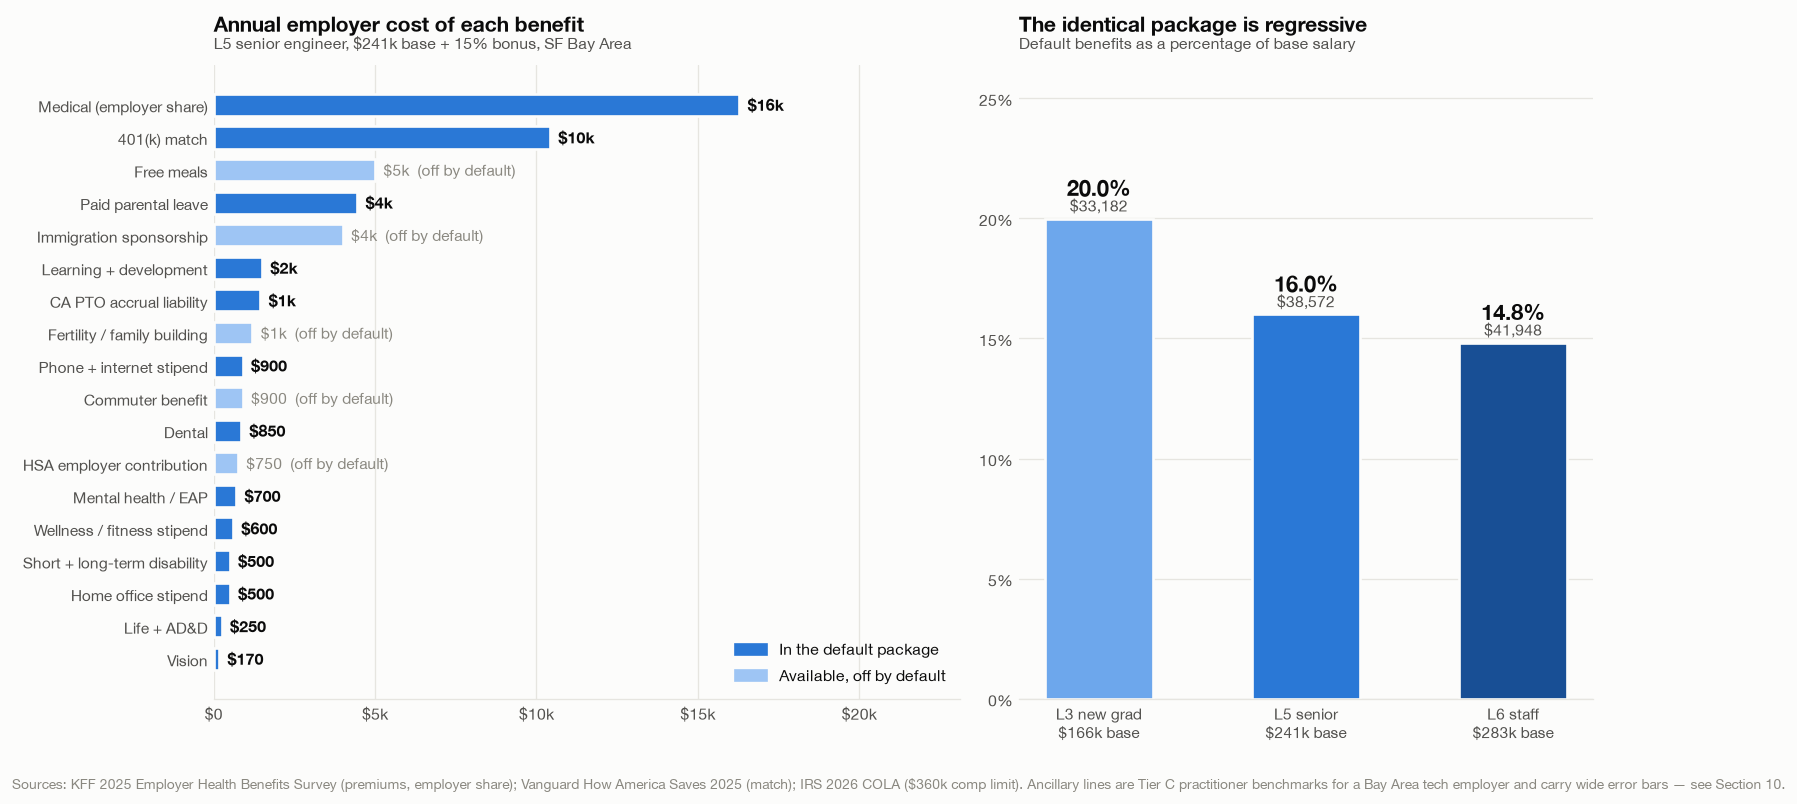

Default package: $38,572 for an L5  (16.0% of base)
The two biggest lines — medical $16,286 and 401(k) match $10,421 — are 69% of it.
Everything else combined is smaller than medical alone.


In [5]:
B  = SRC["benefits"]
KF = B["kff_2025_premiums"]["value"]
ANC = B["ancillary_annual_employer_cost"]["value"]

BENEFIT_PARAMS = dict(
    family_tier_share   = 0.45,   # share of staff on family/dependent coverage
    premium_trend_years = 1.0,    # KFF survey is 2025; trend one year to 2026
    bay_area_uplift     = B["bay_area_tech_premium_uplift"]["default"],   # 1.15
    match_promised_pct  = B["vanguard_401k_match"]["average_promised_pct_of_pay"],  # 4.7%
    match_capture_rate  = B["match_capture_rate"]["default"],             # 0.80
    irs_comp_limit      = SRC["payroll_taxes_2026"]["irs_401a17_comp_limit_2026"]["value"],
    parental_weeks      = B["parental_leave"]["weeks_default"],           # 12
    parental_take_up    = B["parental_leave"]["annual_take_up_rate"],     # 8%
    pto_accrual_pct     = B["ca_pto_accrual_liability"]["pct_of_salary"], # 0.6%
    immigration_onetime = B["immigration_sponsorship"]["default_one_time"],
    expected_tenure_yrs = 3.5,
)

def _medical(base, bonus, p):
    single = KF["single_employer_share"] * (1 + KF["yoy_single"]) ** p["premium_trend_years"]
    family = KF["family_employer_share"] * (1 + KF["yoy_family"]) ** p["premium_trend_years"]
    blended = (1 - p["family_tier_share"]) * single + p["family_tier_share"] * family
    return blended * p["bay_area_uplift"]

# name -> (cost function, default-on?, one-line rationale)
BENEFIT_CATALOG = {
    "Medical (employer share)":  (_medical, True,  "KFF employer share, trended to 2026, Bay Area uplift x1.15"),
    "Dental":                    (lambda b, n, p: ANC["dental"], True,  "blended single/family"),
    "Vision":                    (lambda b, n, p: ANC["vision"], True,  "blended single/family"),
    "Life + AD&D":               (lambda b, n, p: ANC["life_add"], True,  "1-2x salary group term"),
    "Short + long-term disability": (lambda b, n, p: ANC["std_ltd"], True, "group STD/LTD"),
    "Mental health / EAP":       (lambda b, n, p: ANC["eap_mental_health"], True, "Lyra/Spring-style per-seat"),
    "HSA employer contribution": (lambda b, n, p: ANC["hsa_employer_contribution"], False, "only with an HDHP"),
    "401(k) match":              (lambda b, n, p: min(b + n, p["irs_comp_limit"]) * p["match_promised_pct"] * p["match_capture_rate"],
                                  True,  "4.7% promised x 80% capture, capped at $360k of comp"),
    "Paid parental leave":       (lambda b, n, p: b * (p["parental_weeks"] / 52) * p["parental_take_up"],
                                  True,  "12 weeks x 8% annual take-up, amortised across staff"),
    "CA PTO accrual liability":  (lambda b, n, p: b * p["pto_accrual_pct"], True,
                                  "CA must pay out accrued vacation; 'unlimited PTO' zeroes this"),
    "Fertility / family building": (lambda b, n, p: ANC["fertility_family_building"], False, "Carrot/Progyny-style"),
    "Learning + development":    (lambda b, n, p: ANC["learning_development"], True, "conference + course budget"),
    "Wellness / fitness stipend":(lambda b, n, p: ANC["wellness_fitness_stipend"], True, ""),
    "Phone + internet stipend":  (lambda b, n, p: ANC["phone_internet_stipend"], True, ""),
    "Home office stipend":       (lambda b, n, p: ANC["home_office_stipend"], True, "annualised"),
    "Commuter benefit":          (lambda b, n, p: ANC["commuter"], False, ""),
    "Free meals":                (lambda b, n, p: ANC["free_meals"], False, "the single most expensive perk"),
    "Immigration sponsorship":   (lambda b, n, p: p["immigration_onetime"] / p["expected_tenure_yrs"],
                                  False, "H-1B or green card, amortised over expected tenure"),
}
DEFAULT_BENEFITS = [k for k, (_f, d, _n) in BENEFIT_CATALOG.items() if d]

def benefit_costs(base, bonus, selected=None, **kw):
    p = {**BENEFIT_PARAMS, **kw}
    selected = DEFAULT_BENEFITS if selected is None else selected
    return {k: BENEFIT_CATALOG[k][0](base, bonus, p) for k in selected}

# --- how the SAME package lands on three salaries
salaries = [(166_000, 0.10, "L3 new grad"), (241_000, 0.15, "L5 senior"), (283_000, 0.20, "L6 staff")]
allb = sorted(BENEFIT_CATALOG, key=lambda k: -BENEFIT_CATALOG[k][0](241_000, 36_150, BENEFIT_PARAMS))

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13.4, 6.4),
                               gridspec_kw={"width_ratios": [1.3, 1]})

costs_l5 = [BENEFIT_CATALOG[k][0](241_000, 36_150, BENEFIT_PARAMS) for k in allb]
on_l5 = [k in DEFAULT_BENEFITS for k in allb]
cols = [SERIES[0] if o else BLUE_RAMP[2] for o in on_l5]
bars = axA.barh(range(len(allb)), costs_l5, 0.68, color=cols, edgecolor=SURFACE, linewidth=1.6)
for i, (c, o) in enumerate(zip(costs_l5, on_l5)):
    axA.text(c + 260, i, money(c) + ("" if o else "  (off by default)"),
             va="center", color=INK if o else INK_3, fontsize=9.3,
             fontweight="bold" if o else "400")
axA.set_yticks(range(len(allb))); axA.set_yticklabels(allb, fontsize=9.3)
axA.invert_yaxis(); axA.set_xlim(0, max(costs_l5) * 1.42)
frame(axA, "Annual employer cost of each benefit",
      "L5 senior engineer, $241k base + 15% bonus, SF Bay Area",
      money_x=True, ygrid=False, xgrid=True)
axA.add_patch(Rectangle((0, 0), 0, 0, color=SERIES[0], label="In the default package"))
axA.add_patch(Rectangle((0, 0), 0, 0, color=BLUE_RAMP[2], label="Available, off by default"))
axA.legend(loc="lower right")

# -- right: same package, three salaries, shown as % of base
pcts, totals = [], []
for b, bp, _lab in salaries:
    t = sum(benefit_costs(b, b * bp).values())
    totals.append(t); pcts.append(t / b * 100)
xx = np.arange(len(salaries))
bb = axB.bar(xx, pcts, 0.52, color=[BLUE_RAMP[4], BLUE_RAMP[7], BLUE_RAMP[10]],
             edgecolor=SURFACE, linewidth=1.6)
for i, (bar, pc, t) in enumerate(zip(bb, pcts, totals)):
    axB.text(i, pc + 0.95, f"{pc:.1f}%", ha="center", color=INK, fontsize=13, fontweight="bold")
    axB.text(i, pc + 0.30, dollars(t), ha="center", color=INK_2, fontsize=9.5)
axB.set_xticks(xx)
axB.set_xticklabels([f"{lab}\n{money(b)} base" for b, _p, lab in salaries], fontsize=9.3)
axB.set_ylim(0, max(pcts) * 1.32)
axB.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}%"))
frame(axB, "The identical package is regressive",
      "Default benefits as a percentage of base salary")

fig.tight_layout()
source_note(fig, "Sources: KFF 2025 Employer Health Benefits Survey (premiums, employer share); Vanguard How America "
                 "Saves 2025 (match); IRS 2026 COLA ($360k comp limit). Ancillary lines are Tier C practitioner "
                 "benchmarks for a Bay Area tech employer and carry wide error bars — see Section 10.")
plt.show()

print(f"Default package: {dollars(totals[1])} for an L5  ({pcts[1]:.1f}% of base)")
print(f"The two biggest lines — medical {dollars(_medical(241_000, 36_150, BENEFIT_PARAMS))} and "
      f"401(k) match {dollars(min(277_150, 360_000)*0.047*0.80)} — are "
      f"{(_medical(241_000,36_150,BENEFIT_PARAMS)+min(277_150,360_000)*0.047*0.80)/totals[1]:.0%} of it.")
print("Everything else combined is smaller than medical alone.")

<a id="s5"></a>
## 5 · Q4 — The overhead stack nobody budgets for

This tier is where the surprises live, and the single largest item is one that never appears in a
compensation discussion at all.

**Recruiting.** A contingency agency fee for a Bay Area senior engineer runs 18–30% of first-year
base — call it **$53,000** on a $241k salary. Amortised over the 3.5-year expected tenure that is
**~$15,000 a year**, which is larger than the entire medical bill. SHRM's mean cost-per-hire of
$5,475 is the *internal* number: real if you have a sourcing team, wildly optimistic if you don't.
This one parameter swings the answer more than any other, which §10 confirms.

**Office space.** SF asking rents are $70–73/sqft gross (Q3 2026), but vacancy is **29.3%**, so
effective rents after concessions are materially below asking. At 175 sqft/person and a 0.8
desk-sharing ratio that is ~$10k a year. Fully remote: zero — the strongest financial argument for
remote work, and one that gets weaker every quarter as the office market tightens.

**Tools and compute.** Easy to under-count: IDE, GitHub + Copilot, cloud dev environments,
observability, Slack, Atlassian, design seats, plus the engineer's share of dev/staging
infrastructure. $11k combined is a conservative number at a modern AI-era shop; at a company whose
engineers run large training or inference jobs it can exceed the salary.

**Tier 6 (allocated management) is shown separately and off by default** — it is an allocation, not
an incremental cash cost. If you add a 9th engineer to an 8-person team, you do not buy 1/7th of a
manager. If you add the 50th, eventually you do. Use it for unit-economics modelling, never for
"what does this hire cost me next year."

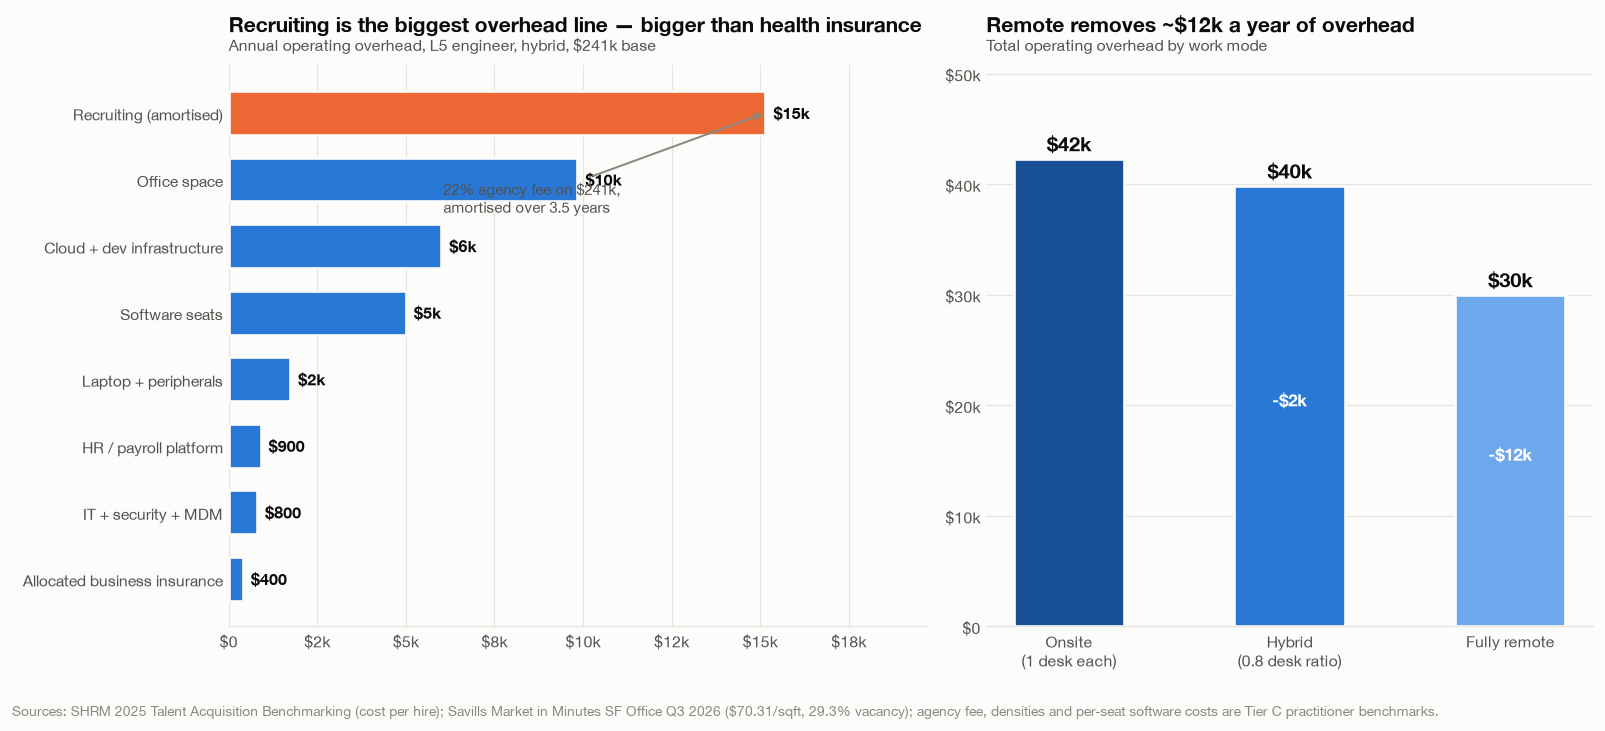

Operating overhead, hybrid L5:  $39,825/yr
Switch recruiting to an internal team: $26,241/yr (-$13,584)
Optional Tier 6 allocated management, span of 7: $74,286/yr — shown separately, OFF by default.


In [6]:
OV = SRC["overheads"]
OPEX = OV["annual_other_opex_per_employee"]["value"]

OVERHEAD_PARAMS = dict(
    recruiting_channel  = "agency",            # "agency" | "internal"
    agency_fee_pct      = OV["agency_fee_pct_of_base"]["default"],     # 22%
    internal_cph        = OV["cost_per_hire"]["shrm_2025_mean_nonexec"],  # $5,475
    expected_tenure_yrs = 3.5,
    rent_psf            = OV["sf_office_asking_rent_psf"]["savills_q3_2026_overall"],  # $70.31
    sqft_per_employee   = OV["sqft_per_employee"]["default"],          # 175
    desk_ratio          = 0.80,                # hybrid desk-sharing
    work_mode           = "hybrid",            # "onsite" | "hybrid" | "remote"
    span_of_control     = OV["span_of_control"]["default"],            # 7
    manager_loaded_cost = 520_000,
)

_MODE_DESK = {"onsite": 1.00, "hybrid": 0.80, "remote": 0.0}

def _recruiting(base, p):
    one_time = (p["agency_fee_pct"] * base if p["recruiting_channel"] == "agency"
                else p["internal_cph"])
    return one_time / p["expected_tenure_yrs"]

def _office(base, p):
    return p["rent_psf"] * p["sqft_per_employee"] * _MODE_DESK[p["work_mode"]]

OVERHEAD_CATALOG = {
    "Recruiting (amortised)":     (lambda b, p: _recruiting(b, p), True,  "agency fee / expected tenure"),
    "Office space":               (lambda b, p: _office(b, p), True,  "rent x sqft x desk ratio"),
    "Laptop + peripherals":       (lambda b, p: OPEX["equipment_amortised"], True, "$5.2k over a 3-year refresh"),
    "Software seats":             (lambda b, p: OPEX["software_seats"], True, "IDE, GitHub, Slack, Atlassian, Copilot"),
    "Cloud + dev infrastructure": (lambda b, p: OPEX["cloud_dev_infra"], True, "dev/staging share; can dwarf salary at an AI shop"),
    "IT + security + MDM":        (lambda b, p: OPEX["it_security_device_mgmt"], True, ""),
    "HR / payroll platform":      (lambda b, p: OPEX["hr_payroll_platform"], True, "Rippling/Gusto-class per-seat"),
    "Allocated business insurance": (lambda b, p: OPEX["allocated_business_insurance"], True, "D&O / E&O / cyber share"),
}
DEFAULT_OVERHEADS = [k for k, (_f, d, _n) in OVERHEAD_CATALOG.items() if d]

def overhead_costs(base, selected=None, **kw):
    p = {**OVERHEAD_PARAMS, **kw}
    selected = DEFAULT_OVERHEADS if selected is None else selected
    return {k: OVERHEAD_CATALOG[k][0](base, p) for k in selected}

def allocated_management(base, **kw):
    p = {**OVERHEAD_PARAMS, **kw}
    return p["manager_loaded_cost"] / p["span_of_control"]

# --- work mode comparison
modes = ["onsite", "hybrid", "remote"]
fig, (axA, axB) = plt.subplots(1, 2, figsize=(13.4, 5.8),
                               gridspec_kw={"width_ratios": [1.15, 1]})

oh = overhead_costs(241_000)
items = sorted(oh, key=lambda k: -oh[k])
vals = [oh[k] for k in items]
bars = axA.barh(range(len(items)), vals, 0.66,
                color=[SERIES[1]] + [BLUE_RAMP[7]] * (len(items) - 1),
                edgecolor=SURFACE, linewidth=1.6)
for i, v in enumerate(vals):
    axA.text(v + 230, i, money(v), va="center", color=INK, fontsize=9.6, fontweight="bold")
axA.set_yticks(range(len(items))); axA.set_yticklabels(items, fontsize=9.4)
axA.invert_yaxis(); axA.set_xlim(0, max(vals) * 1.3)
frame(axA, "Recruiting is the biggest overhead line — bigger than health insurance",
      "Annual operating overhead, L5 engineer, hybrid, $241k base",
      money_x=True, ygrid=False, xgrid=True)
axA.annotate("22% agency fee on $241k,\namortised over 3.5 years",
             xy=(vals[0], 0), xytext=(vals[0] * 0.40, 1.5),
             color=INK_2, fontsize=9,
             arrowprops=dict(arrowstyle="->", color=INK_3, lw=1.2))

tot_by_mode = [sum(overhead_costs(241_000, work_mode=m).values()) for m in modes]
xx = np.arange(3)
bb = axB.bar(xx, tot_by_mode, 0.5, color=[BLUE_RAMP[10], BLUE_RAMP[7], BLUE_RAMP[4]],
             edgecolor=SURFACE, linewidth=1.6)
for i, v in enumerate(tot_by_mode):
    axB.text(i, v + 700, money(v), ha="center", color=INK, fontsize=12, fontweight="bold")
    if i:
        axB.text(i, v / 2, f"-{money(tot_by_mode[0]-v)}", ha="center",
                 color="white", fontsize=10, fontweight="bold")
axB.set_xticks(xx); axB.set_xticklabels(["Onsite\n(1 desk each)", "Hybrid\n(0.8 desk ratio)", "Fully remote"])
axB.set_ylim(0, max(tot_by_mode) * 1.2)
frame(axB, "Remote removes ~$12k a year of overhead",
      "Total operating overhead by work mode", money_y=True)

fig.tight_layout()
source_note(fig, "Sources: SHRM 2025 Talent Acquisition Benchmarking (cost per hire); Savills Market in Minutes "
                 "SF Office Q3 2026 ($70.31/sqft, 29.3% vacancy); agency fee, densities and per-seat software costs "
                 "are Tier C practitioner benchmarks.")
plt.show()

print(f"Operating overhead, hybrid L5:  {dollars(tot_by_mode[1])}/yr")
print(f"Switch recruiting to an internal team: "
      f"{dollars(sum(overhead_costs(241_000, recruiting_channel='internal').values()))}/yr "
      f"(-{dollars(tot_by_mode[1]-sum(overhead_costs(241_000, recruiting_channel='internal').values()))})")
print(f"Optional Tier 6 allocated management, span of {OVERHEAD_PARAMS['span_of_control']}: "
      f"{dollars(allocated_management(241_000))}/yr — shown separately, OFF by default.")

<a id="s6"></a>
## 6 · Q5 — Putting it together: the fully-loaded multiple

Now the waterfall. One engineer, L5 senior, $241k base, 15% target bonus, hybrid, default benefits,
agency-sourced, with an annualised equity grant.

Then the question that matters: **what multiple of base salary is the real cost?** The answer is
not a constant — it falls as salary rises, because the two largest non-salary tiers (statutory tax
and flat-dollar benefits) are both capped.

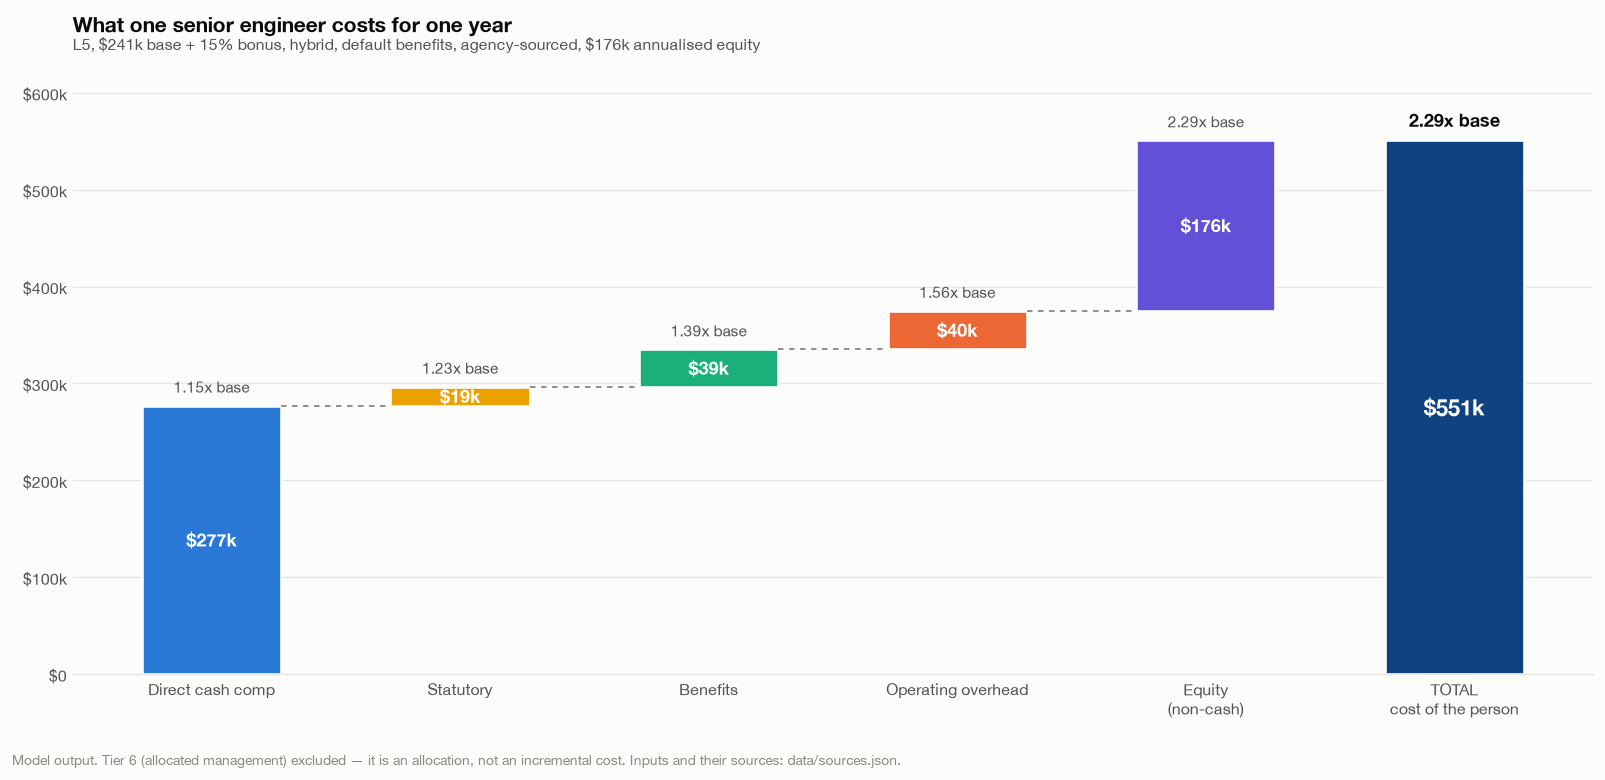

Cash cost (tiers 1-4):        $375,036   =  1.56x base salary
Plus equity (GAAP, non-cash): $551,036   =  2.29x base salary
Cash above base salary:       $134,036 that never appears in the offer letter


In [7]:
def total_cost(base, bonus_pct=0.15, equity_annual=0.0, benefits=None, overheads=None,
               include_allocated_mgmt=False, **kw):
    """Full six-tier cost of one employee for one year. Returns a tidy DataFrame."""
    bonus = base * bonus_pct
    tax   = employer_payroll_taxes(base + bonus, equity_vest_value=equity_annual,
                                   **{k: v for k, v in kw.items() if k in TAX_DEFAULTS})
    ben   = benefit_costs(base, bonus, benefits, **{k: v for k, v in kw.items() if k in BENEFIT_PARAMS})
    ovh   = overhead_costs(base, overheads, **{k: v for k, v in kw.items() if k in OVERHEAD_PARAMS})

    rows  = [("1 · Direct cash comp", "Base salary", base),
             ("1 · Direct cash comp", "Cash bonus", bonus)]
    rows += [("2 · Statutory", k, v) for k, v in tax.items()]
    rows += [("3 · Benefits", k, v) for k, v in ben.items()]
    rows += [("4 · Operating overhead", k, v) for k, v in ovh.items()]
    if equity_annual:
        rows += [("5 · Equity (non-cash)", "Stock-based comp expense", equity_annual)]
    if include_allocated_mgmt:
        rows += [("6 · Allocated org overhead", "Share of management",
                  allocated_management(base, **{k: v for k, v in kw.items() if k in OVERHEAD_PARAMS}))]
    return pd.DataFrame(rows, columns=["tier", "item", "cost"])

def summarise(df, base):
    t = df.groupby("tier", sort=True)["cost"].sum()
    cash   = t[[i for i in t.index if not i.startswith(("5", "6"))]].sum()
    equity = t.get("5 · Equity (non-cash)", 0.0)
    alloc  = t.get("6 · Allocated org overhead", 0.0)
    return dict(tiers=t, cash=cash, equity=equity, allocated=alloc,
                total=cash + equity + alloc,
                mult_cash=cash / base, mult_total=(cash + equity) / base)

BASELINE = dict(base=241_000, bonus_pct=0.15, equity_annual=176_000)
df0 = total_cost(**BASELINE)
s0  = summarise(df0, BASELINE["base"])

# --- waterfall
order = ["1 · Direct cash comp", "2 · Statutory", "3 · Benefits",
         "4 · Operating overhead", "5 · Equity (non-cash)"]
tiervals = [s0["tiers"][t] for t in order]
tiercols = [SERIES[0], SERIES[3], SERIES[2], SERIES[1], SERIES[6]]

fig, ax = plt.subplots(figsize=(13.4, 6.2))
running = 0.0
for i, (name, v, c) in enumerate(zip(order, tiervals, tiercols)):
    ax.bar(i, v, 0.56, bottom=running, color=c, edgecolor=SURFACE, linewidth=1.6)
    ax.text(i, running + v / 2, money(v), ha="center", va="center", color="white",
            fontsize=10.5, fontweight="bold")
    ax.text(i, running + v + 10_000, f"{(running+v)/BASELINE['base']:.2f}x base",
            ha="center", va="bottom", color=INK_2, fontsize=9.2)
    if i < len(order) - 1:
        ax.plot([i + 0.28, i + 0.72], [running + v, running + v],
                color=INK_3, lw=1.1, ls=(0, (3, 3)))
    running += v
ax.bar(len(order), running, 0.56, color=BLUE_RAMP[11], edgecolor=SURFACE, linewidth=1.6)
ax.text(len(order), running / 2, money(running), ha="center", va="center",
        color="white", fontsize=13, fontweight="bold")
ax.text(len(order), running + 10_000, f"{running/BASELINE['base']:.2f}x base",
        ha="center", va="bottom", color=INK, fontsize=10.5, fontweight="bold")

ax.set_xticks(range(len(order) + 1))
ax.set_xticklabels([o.split(" · ")[1].replace(" (non-cash)", "\n(non-cash)") for o in order]
                   + ["TOTAL\ncost of the person"], fontsize=9.6)
ax.set_ylim(0, running * 1.14)
frame(ax, "What one senior engineer costs for one year",
      "L5, $241k base + 15% bonus, hybrid, default benefits, agency-sourced, $176k annualised equity",
      money_y=True)
fig.tight_layout()
source_note(fig, "Model output. Tier 6 (allocated management) excluded — it is an allocation, not an incremental cost. "
                 "Inputs and their sources: data/sources.json.")
plt.show()

print(f"Cash cost (tiers 1-4):        {dollars(s0['cash'])}   =  {s0['mult_cash']:.2f}x base salary")
print(f"Plus equity (GAAP, non-cash): {dollars(s0['total'])}   =  {s0['mult_total']:.2f}x base salary")
print(f"Cash above base salary:       {dollars(s0['cash'] - BASELINE['base'])} that never appears in the offer letter")

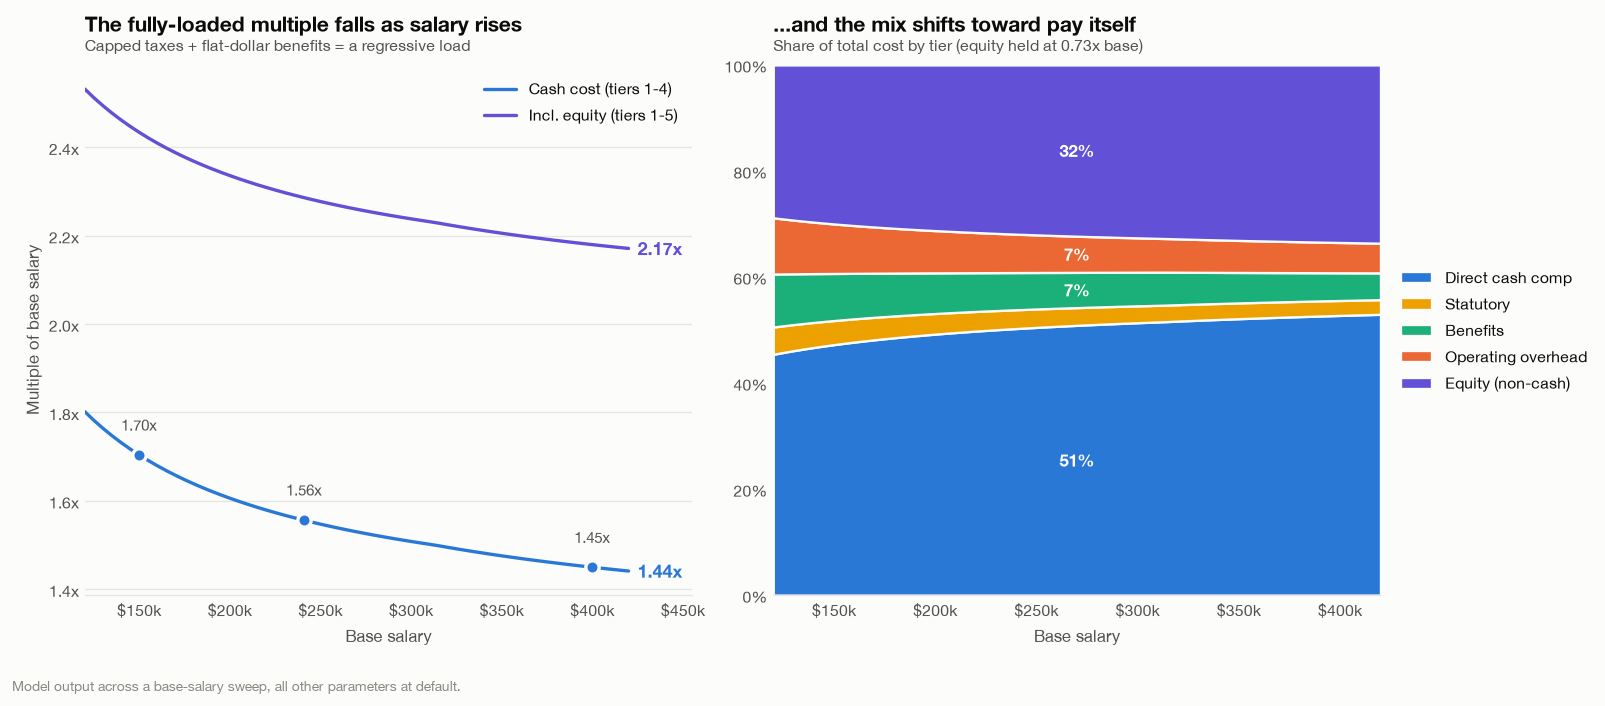

CALIBRATION CHECK — model vs. BLS Employer Costs for Employee Compensation, June 2026
--------------------------------------------------------------------------------------
BLS, professional occupations, insurance + retirement + legally required, as a load on wages:
    25.6%   (national, all private industry)
This model, same three categories, as a load on cash comp:
    20.9%   (Bay Area, senior engineer)

The model sits -4.6% vs. the national benchmark. That gap is the
expected direction and magnitude: Social Security caps out far below a senior engineer's
salary (pushing the model DOWN), while Bay Area health plans and a 4.7% match push it UP.
A bottom-up model that disagreed with BLS by 15+ points would be a model with a bug in it.


In [8]:
# --- the multiple is not a constant -----------------------------------------
sweep = np.arange(120_000, 420_001, 5_000)
m_cash, m_total, tier_pct = [], [], {t: [] for t in order}
for b in sweep:
    d = total_cost(base=b, bonus_pct=0.15, equity_annual=0.73 * b)
    s = summarise(d, b)
    m_cash.append(s["mult_cash"]); m_total.append(s["mult_total"])
    for t in order:
        tier_pct[t].append(s["tiers"][t] / s["total"] * 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 5.6))

ax1.plot(sweep, m_cash, color=SERIES[0], label="Cash cost (tiers 1-4)")
ax1.plot(sweep, m_total, color=SERIES[6], label="Incl. equity (tiers 1-5)")
for arr, c, lab in [(m_cash, SERIES[0], "cash"), (m_total, SERIES[6], "total")]:
    ax1.text(sweep[-1] + 5_000, arr[-1], f"{arr[-1]:.2f}x", color=c,
             fontsize=10.5, fontweight="bold", va="center")
for b in (150_000, 241_000, 400_000):
    i = int(np.argmin(np.abs(sweep - b)))
    ax1.plot([b], [m_cash[i]], "o", color=SERIES[0], ms=8,
             markeredgecolor=SURFACE, markeredgewidth=2)
    ax1.annotate(f"{m_cash[i]:.2f}x", xy=(b, m_cash[i]), xytext=(b, m_cash[i] + 0.055),
                 ha="center", color=INK_2, fontsize=9)
ax1.set_xlim(120_000, 455_000)
frame(ax1, "The fully-loaded multiple falls as salary rises",
      "Capped taxes + flat-dollar benefits = a regressive load",
      xlabel="Base salary", ylabel="Multiple of base salary", money_x=True)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.1f}x"))
ax1.legend(loc="upper right")

bot = np.zeros(len(sweep))
for t, c in zip(order, tiercols):
    arr = np.array(tier_pct[t])
    ax2.fill_between(sweep, bot, bot + arr, color=c, label=t.split(" · ")[1],
                     linewidth=1.4, edgecolor=SURFACE)
    mid = len(sweep) // 2
    if arr[mid] > 6:
        ax2.text(sweep[mid], bot[mid] + arr[mid] / 2, f"{arr[mid]:.0f}%",
                 ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    bot += arr
ax2.set_ylim(0, 100); ax2.set_xlim(sweep[0], sweep[-1])
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}%"))
frame(ax2, "...and the mix shifts toward pay itself",
      "Share of total cost by tier (equity held at 0.73x base)",
      xlabel="Base salary", money_x=True)
ax2.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))

fig.tight_layout()
source_note(fig, "Model output across a base-salary sweep, all other parameters at default.")
plt.show()

# --- calibration against BLS
bls = SRC["bls_ecec"]["professional_and_related_occupations"]
# BLS 'benefits' minus paid leave and supplemental pay (both already inside salary/bonus here)
bls_comparable = (bls["insurance"] + bls["retirement_and_savings"] + bls["legally_required"]) / bls["wages_and_salaries"]
model_comparable = (s0["tiers"]["2 · Statutory"] + s0["tiers"]["3 · Benefits"]) / (BASELINE["base"] * 1.15)

print("CALIBRATION CHECK — model vs. BLS Employer Costs for Employee Compensation, June 2026")
print("-" * 86)
print(f"BLS, professional occupations, insurance + retirement + legally required, as a load on wages:")
print(f"    {bls_comparable:.1%}   (national, all private industry)")
print(f"This model, same three categories, as a load on cash comp:")
print(f"    {model_comparable:.1%}   (Bay Area, senior engineer)")
print()
print(f"The model sits {model_comparable - bls_comparable:+.1%} vs. the national benchmark. That gap is the")
print("expected direction and magnitude: Social Security caps out far below a senior engineer's")
print("salary (pushing the model DOWN), while Bay Area health plans and a 4.7% match push it UP.")
print("A bottom-up model that disagreed with BLS by 15+ points would be a model with a bug in it.")

<a id="s7"></a>
## 7 · Q6 — Interactive: choose a salary and a benefits package

The next cell builds a live control panel: **base salary slider**, **bonus %**, **equity**,
**level preset**, **work mode**, **recruiting channel**, and a **checkbox for every benefit and
overhead line**. Change anything and the cost model, the waterfall and the headline multiple
re-compute.

It needs a running kernel (`jupyter lab`) with `ipywidgets` installed. If widgets aren't available
it degrades to a plain function call with the same arguments, printed below the controls — and the
cell after it always renders a static comparison so the notebook still reads as a document.

In [9]:
def cost_report(base=241_000, bonus_pct=0.15, equity_annual=176_000,
                work_mode="hybrid", recruiting_channel="agency",
                family_tier_share=0.45, bay_area_uplift=1.15,
                match_promised_pct=0.047, expected_tenure_yrs=3.5,
                benefits=None, overheads=None, include_allocated_mgmt=False,
                quiet=False):
    """Compute + draw the cost of one hire under the chosen options."""
    df = total_cost(base=base, bonus_pct=bonus_pct, equity_annual=equity_annual,
                    benefits=benefits, overheads=overheads,
                    include_allocated_mgmt=include_allocated_mgmt,
                    work_mode=work_mode, recruiting_channel=recruiting_channel,
                    family_tier_share=family_tier_share, bay_area_uplift=bay_area_uplift,
                    match_promised_pct=match_promised_pct,
                    expected_tenure_yrs=expected_tenure_yrs)
    s = summarise(df, base)
    if quiet:
        return df, s

    tiers = [t for t in s["tiers"].index]
    cmap  = {"1 · Direct cash comp": SERIES[0], "2 · Statutory": SERIES[3],
             "3 · Benefits": SERIES[2], "4 · Operating overhead": SERIES[1],
             "5 · Equity (non-cash)": SERIES[6], "6 · Allocated org overhead": SERIES[4]}

    fig = plt.figure(figsize=(13.4, 5.9))
    gs  = fig.add_gridspec(1, 2, width_ratios=[1, 1.45], wspace=0.28)
    axL, axR = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

    # headline stat tile (no plot — a hero number does this job better than a chart)
    axL.axis("off")
    axL.text(0, 0.95, "TOTAL ANNUAL COST", color=INK_3, fontsize=10,
             fontweight="bold", transform=axL.transAxes, va="top")
    axL.text(0, 0.80, money(s["total"]), color=INK, fontsize=42,
             fontweight="bold", transform=axL.transAxes, va="top")
    axL.text(0, 0.60, f"{s['total']/base:.2f}x base salary", color=SERIES[0],
             fontsize=17, fontweight="bold", transform=axL.transAxes, va="top")
    lines = [
        ("Cash out the door (tiers 1-4)", money(s["cash"]), f"{s['mult_cash']:.2f}x base"),
        ("Non-cash equity expense", money(s["equity"]), f"{s['equity']/base:.2f}x base" if s["equity"] else "-"),
        ("Hidden cost above base salary", money(s["cash"] - base), f"+{(s['cash']-base)/base:.0%}"),
        ("Effective cost per working hour", money(s["cash"] / 1_880), "1,880 productive hrs/yr"),
    ]
    y = 0.44
    for label, v1, v2 in lines:
        axL.text(0, y, label, color=INK_2, fontsize=10, transform=axL.transAxes, va="top")
        axL.text(0, y - 0.065, v1, color=INK, fontsize=15, fontweight="bold",
                 transform=axL.transAxes, va="top")
        axL.text(0.52, y - 0.055, v2, color=INK_3, fontsize=10,
                 transform=axL.transAxes, va="top")
        y -= 0.155

    # stacked bar of tiers
    bottom = 0.0
    for t in tiers:
        v = s["tiers"][t]
        axR.bar(0, v, 0.42, bottom=bottom, color=cmap[t], edgecolor=SURFACE,
                linewidth=1.8, label=t)
        if v / s["total"] > 0.035:
            axR.text(0, bottom + v / 2, f"{t.split(' · ')[1]}   {money(v)}",
                     ha="center", va="center", color="white", fontsize=9.6, fontweight="bold")
        bottom += v
    axR.set_xlim(-0.6, 0.6); axR.set_xticks([])
    axR.set_ylim(0, bottom * 1.06)
    frame(axR, "Cost stack",
          f"{money(base)} base · {bonus_pct:.0%} bonus · {work_mode} · "
          f"{recruiting_channel} recruiting · {len(benefits or DEFAULT_BENEFITS)} benefits selected",
          money_y=True)
    axR.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), reverse=True)
    plt.show()

    show = df.copy()
    show["% of total"] = show["cost"] / s["total"]
    display(show.sort_values(["tier", "cost"], ascending=[True, False])
            .style.format({"cost": money, "% of total": "{:.1%}"})
            .hide(axis="index").set_caption("Every line item"))
    return df, s

# ---- live controls ----------------------------------------------------------
LEVEL_PRESETS = {
    "L3 · New grad ($166k)":        dict(base=166_000, bonus_pct=0.10, equity_annual=44_300),
    "L4 · SWE II ($204k)":          dict(base=204_000, bonus_pct=0.12, equity_annual=123_000),
    "L5 · Senior ($241k)":          dict(base=241_000, bonus_pct=0.15, equity_annual=176_000),
    "L6 · Staff ($283k)":           dict(base=283_000, bonus_pct=0.20, equity_annual=338_000),
    "Seed-stage startup ($180k)":   dict(base=180_000, bonus_pct=0.00, equity_annual=60_000),
}

try:
    import ipywidgets as W
    from IPython.display import display as _disp

    w_level  = W.Dropdown(options=list(LEVEL_PRESETS), value="L5 · Senior ($241k)",
                          description="Preset:", style={"description_width": "130px"},
                          layout=W.Layout(width="330px"))
    w_base   = W.IntSlider(value=241_000, min=100_000, max=500_000, step=1_000,
                           description="Base salary:", readout_format=",d",
                           style={"description_width": "130px"}, layout=W.Layout(width="520px"))
    w_bonus  = W.FloatSlider(value=0.15, min=0.0, max=0.40, step=0.01,
                             description="Target bonus:", readout_format=".0%",
                             style={"description_width": "130px"}, layout=W.Layout(width="520px"))
    w_equity = W.IntSlider(value=176_000, min=0, max=500_000, step=5_000,
                           description="Equity /yr:", readout_format=",d",
                           style={"description_width": "130px"}, layout=W.Layout(width="520px"))
    w_mode   = W.ToggleButtons(options=["onsite", "hybrid", "remote"], value="hybrid",
                               description="Work mode:", style={"description_width": "130px"})
    w_recr   = W.ToggleButtons(options=["agency", "internal"], value="agency",
                               description="Recruiting:", style={"description_width": "130px"})
    w_fam    = W.FloatSlider(value=0.45, min=0.0, max=1.0, step=0.05,
                             description="On family plan:", readout_format=".0%",
                             style={"description_width": "130px"}, layout=W.Layout(width="520px"))
    w_uplift = W.FloatSlider(value=1.15, min=1.0, max=1.40, step=0.01,
                             description="Bay Area uplift:", readout_format=".2f",
                             style={"description_width": "130px"}, layout=W.Layout(width="520px"))
    w_match  = W.FloatSlider(value=0.047, min=0.0, max=0.10, step=0.005,
                             description="401(k) match:", readout_format=".1%",
                             style={"description_width": "130px"}, layout=W.Layout(width="520px"))
    w_tenure = W.FloatSlider(value=3.5, min=1.0, max=8.0, step=0.5,
                             description="Expected tenure:", readout_format=".1f",
                             style={"description_width": "130px"}, layout=W.Layout(width="520px"))
    w_mgmt   = W.Checkbox(value=False, description="Include Tier 6 allocated management",
                          indent=False)

    ben_boxes = {k: W.Checkbox(value=(k in DEFAULT_BENEFITS), description=k, indent=False,
                               layout=W.Layout(width="310px"))
                 for k in BENEFIT_CATALOG}
    ovh_boxes = {k: W.Checkbox(value=(k in DEFAULT_OVERHEADS), description=k, indent=False,
                               layout=W.Layout(width="310px"))
                 for k in OVERHEAD_CATALOG}

    def _apply_preset(change):
        p = LEVEL_PRESETS[change["new"]]
        w_base.value, w_bonus.value, w_equity.value = p["base"], p["bonus_pct"], p["equity_annual"]
    w_level.observe(_apply_preset, names="value")

    out = W.Output()

    def _refresh(_=None):
        with out:
            out.clear_output(wait=True)
            cost_report(base=w_base.value, bonus_pct=w_bonus.value, equity_annual=w_equity.value,
                        work_mode=w_mode.value, recruiting_channel=w_recr.value,
                        family_tier_share=w_fam.value, bay_area_uplift=w_uplift.value,
                        match_promised_pct=w_match.value, expected_tenure_yrs=w_tenure.value,
                        benefits=[k for k, b in ben_boxes.items() if b.value],
                        overheads=[k for k, b in ovh_boxes.items() if b.value],
                        include_allocated_mgmt=w_mgmt.value)

    for w in [w_base, w_bonus, w_equity, w_mode, w_recr, w_fam, w_uplift,
              w_match, w_tenure, w_mgmt, *ben_boxes.values(), *ovh_boxes.values()]:
        w.observe(_refresh, names="value")

    def _hdr(t):
        return W.HTML(f"<div style='font:700 12px system-ui;color:#52514e;"
                      f"margin:10px 0 4px'>{t}</div>")

    panel = W.VBox([
        _hdr("OFFER"),
        w_level, w_base, w_bonus, w_equity,
        _hdr("WORKING ARRANGEMENT"), w_mode, w_recr, w_tenure,
        _hdr("BENEFIT ASSUMPTIONS"), w_fam, w_uplift, w_match,
        _hdr("BENEFITS OFFERED"),
        W.Box(list(ben_boxes.values()),
              layout=W.Layout(display="flex", flex_flow="row wrap", width="960px")),
        _hdr("OPERATING OVERHEAD INCLUDED"),
        W.Box(list(ovh_boxes.values()),
              layout=W.Layout(display="flex", flex_flow="row wrap", width="960px")),
        _hdr("ACCOUNTING VIEW"), w_mgmt,
    ])
    _disp(W.VBox([panel, out]))
    _refresh()
    print("Interactive controls active — move a slider or tick a benefit to recompute.")

except Exception as exc:                                    # pragma: no cover
    print(f"ipywidgets unavailable ({exc.__class__.__name__}); falling back to a direct call.")
    print("Edit the arguments below and re-run this cell.\n")
    cost_report(base=241_000, bonus_pct=0.15, equity_annual=176_000,
                work_mode="hybrid", recruiting_channel="agency",
                benefits=DEFAULT_BENEFITS, overheads=DEFAULT_OVERHEADS)

Interactive controls active — move a slider or tick a benefit to recompute.


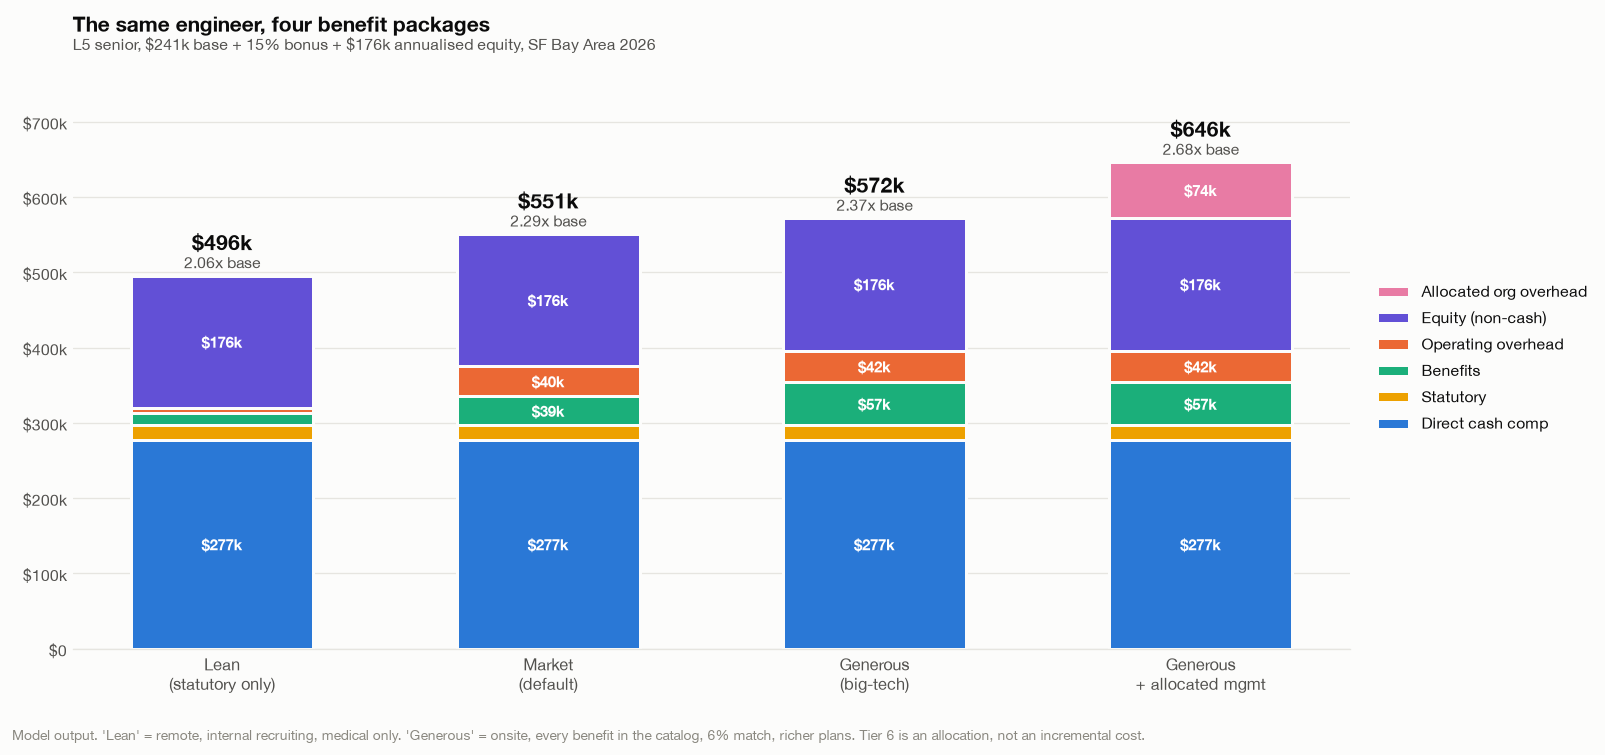

,Cash cost,Equity (non-cash),Allocated mgmt,TOTAL,x base salary
Lean (statutory only),$320k,$176k,$0,$496k,2.06x
Market (default),$375k,$176k,$0,$551k,2.29x
Generous (big-tech),$396k,$176k,$0,$572k,2.37x
Generous + allocated mgmt,$396k,$176k,$74k,$646k,2.68x



Same person, same salary: the benefits-and-overhead decisions move total cost by 1.30x.
The lean-to-market gap alone is $55,378 a year on one person.


In [10]:
# --- Static comparison, always rendered -------------------------------------
# Four packages against the same L5 offer, so the notebook reads as a document
# even without a live kernel.
PACKAGES = {
    "Lean\n(statutory only)": dict(
        benefits=["Medical (employer share)"],
        overheads=["Laptop + peripherals", "Software seats"],
        work_mode="remote", recruiting_channel="internal"),
    "Market\n(default)": dict(
        benefits=DEFAULT_BENEFITS, overheads=DEFAULT_OVERHEADS,
        work_mode="hybrid", recruiting_channel="agency"),
    "Generous\n(big-tech)": dict(
        benefits=list(BENEFIT_CATALOG), overheads=DEFAULT_OVERHEADS,
        work_mode="onsite", recruiting_channel="agency", bay_area_uplift=1.30,
        match_promised_pct=0.06, family_tier_share=0.55),
    "Generous\n+ allocated mgmt": dict(
        benefits=list(BENEFIT_CATALOG), overheads=DEFAULT_OVERHEADS,
        work_mode="onsite", recruiting_channel="agency", bay_area_uplift=1.30,
        match_promised_pct=0.06, family_tier_share=0.55, include_allocated_mgmt=True),
}

res = {}
for name, kwargs in PACKAGES.items():
    d, s = cost_report(base=241_000, bonus_pct=0.15, equity_annual=176_000, quiet=True, **kwargs)
    res[name] = s

fig, ax = plt.subplots(figsize=(13.4, 6.0))
names = list(res)
tiers_all = ["1 · Direct cash comp", "2 · Statutory", "3 · Benefits",
             "4 · Operating overhead", "5 · Equity (non-cash)", "6 · Allocated org overhead"]
tcols = [SERIES[0], SERIES[3], SERIES[2], SERIES[1], SERIES[6], SERIES[4]]
x = np.arange(len(names))
bottom = np.zeros(len(names))
for t, c in zip(tiers_all, tcols):
    vals = np.array([res[n]["tiers"].get(t, 0.0) for n in names])
    if vals.sum() == 0:
        continue
    ax.bar(x, vals, 0.56, bottom=bottom, color=c, label=t.split(" · ")[1],
           edgecolor=SURFACE, linewidth=1.8)
    for xi, (b, v) in enumerate(zip(bottom, vals)):
        if v > 26_000:
            ax.text(xi, b + v / 2, money(v), ha="center", va="center",
                    color="white", fontsize=9.2, fontweight="bold")
    bottom += vals
for xi, (n, tot) in enumerate(zip(names, bottom)):
    ax.text(xi, tot + 34_000, money(tot), ha="center", color=INK, fontsize=12.5, fontweight="bold")
    ax.text(xi, tot + 10_000, f"{tot/241_000:.2f}x base", ha="center", color=INK_2, fontsize=9.4)
ax.set_xticks(x); ax.set_xticklabels(names, fontsize=9.8)
ax.set_ylim(0, bottom.max() * 1.20)
frame(ax, "The same engineer, four benefit packages",
      "L5 senior, $241k base + 15% bonus + $176k annualised equity, SF Bay Area 2026",
      money_y=True)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), reverse=True)
fig.tight_layout()
source_note(fig, "Model output. 'Lean' = remote, internal recruiting, medical only. 'Generous' = onsite, every benefit "
                 "in the catalog, 6% match, richer plans. Tier 6 is an allocation, not an incremental cost.")
plt.show()

comp = pd.DataFrame({n: {"Cash cost": res[n]["cash"], "Equity (non-cash)": res[n]["equity"],
                         "Allocated mgmt": res[n]["allocated"], "TOTAL": res[n]["total"],
                         "x base salary": res[n]["total"] / 241_000} for n in names}).T
display(comp.style.format({c: money for c in comp.columns[:-1]} | {"x base salary": "{:.2f}x"}))
spread = comp["TOTAL"].max() / comp["TOTAL"].min()
print(f"\nSame person, same salary: the benefits-and-overhead decisions move total cost by {spread:.2f}x.")
lean_total, market_total = res[names[0]]["total"], res[names[1]]["total"]
print(f"The lean-to-market gap alone is {dollars(market_total - lean_total)} a year on one person.")

<a id="s8"></a>
## 8 · Q7 — Equity: what it costs vs. what it's worth

Equity is the one line where the employer's cost and the employee's benefit are *different
numbers measured in different units*, and pretending otherwise is how offers get mis-sold.

- **The employer's cost** is GAAP stock-based compensation: grant-date fair value, recognised over
  the vesting period, whether or not the share price moves, whether or not the employee stays past
  the cliff (forfeitures reverse the expense, but the expense was real until then). It is non-cash
  for the company and dilutive for existing shareholders.
- **The employee's benefit** is a random variable. For public RSUs it is a well-behaved one. For
  private options it is a lottery ticket with a fee attached — you must survive to the cliff, keep
  vesting, the company must reach liquidity, the price must exceed your strike, and you must have
  the cash to exercise inside a 90-day window.

The SEC filings below give the first number precisely, straight from the 10-Ks. The next section
attacks the second one with simulation.

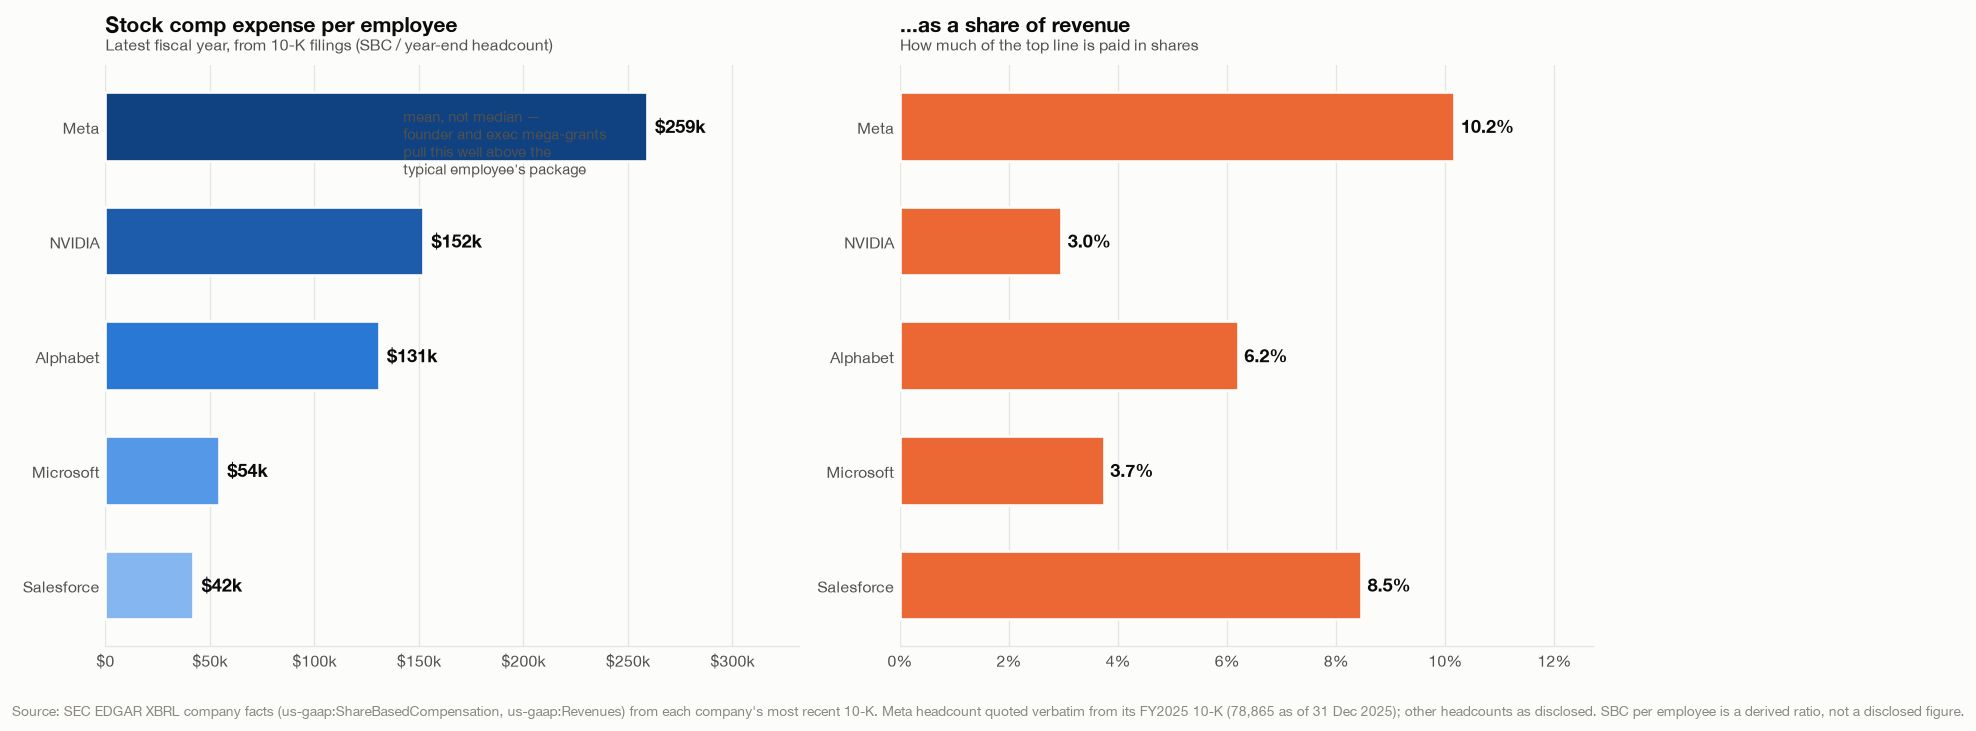

Company,FY,SBC,Revenue,Employees,SBC_per_emp,Rev_per_emp,SBC_pct_rev
Meta,FY2025,"$20,430.00M","$200,970.00M","78,865",$259k,$2.55M,10.2%
NVIDIA,FY2026,"$6,386.00M","$215,938.00M","42,000",$152k,$5.14M,3.0%
Alphabet,FY2025,"$24,953.00M","$402,836.00M","190,820",$131k,$2.11M,6.2%
Microsoft,FY2026,"$12,400.00M","$331,840.00M","228,000",$54k,$1.46M,3.7%
Salesforce,FY2026,"$3,510.00M","$41,520.00M","83,334",$42k,$498k,8.5%



Range of SBC per employee across these filers: $42,120 to $259,050
If your mental model of 'equity cost' is a round $100k, the filings say the serious players
spend between half and three times that, per head, every year.


In [11]:
EQ = SRC["equity"]["sec_filings"]["value"]
rows = []
for co, d in EQ.items():
    if d["sbc_usd"] is None:
        continue
    rows.append(dict(Company=co, FY=d["fiscal_year"].split(" ")[0],
                     SBC=d["sbc_usd"], Revenue=d["revenue_usd"], Employees=d["employees"],
                     SBC_per_emp=d["sbc_usd"] / d["employees"],
                     Rev_per_emp=d["revenue_usd"] / d["employees"],
                     SBC_pct_rev=d["sbc_usd"] / d["revenue_usd"]))
eq = pd.DataFrame(rows).sort_values("SBC_per_emp", ascending=False).reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 5.8))

cols1 = [BLUE_RAMP[11 - min(i * 2, 8)] for i in range(len(eq))]
b1 = ax1.barh(eq.Company, eq.SBC_per_emp, 0.6, color=cols1, edgecolor=SURFACE, linewidth=1.6)
for i, (v, c) in enumerate(zip(eq.SBC_per_emp, eq.Company)):
    ax1.text(v + 4_000, i, money(v), va="center", color=INK, fontsize=10.5, fontweight="bold")
ax1.invert_yaxis(); ax1.set_xlim(0, eq.SBC_per_emp.max() * 1.28)
frame(ax1, "Stock comp expense per employee",
      "Latest fiscal year, from 10-K filings (SBC / year-end headcount)",
      money_x=True, ygrid=False, xgrid=True)
ax1.annotate("mean, not median —\nfounder and exec mega-grants\npull this well above the\ntypical employee's package",
             xy=(eq.SBC_per_emp.iloc[0] * 0.55, 0.42), color=INK_2, fontsize=8.8)

b2 = ax2.barh(eq.Company, eq.SBC_pct_rev * 100, 0.6, color=SERIES[1],
              edgecolor=SURFACE, linewidth=1.6)
for i, v in enumerate(eq.SBC_pct_rev * 100):
    ax2.text(v + 0.12, i, f"{v:.1f}%", va="center", color=INK, fontsize=10.5, fontweight="bold")
ax2.invert_yaxis(); ax2.set_xlim(0, (eq.SBC_pct_rev * 100).max() * 1.25)
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}%"))
frame(ax2, "...as a share of revenue",
      "How much of the top line is paid in shares",
      ygrid=False, xgrid=True)

fig.tight_layout()
source_note(fig, "Source: SEC EDGAR XBRL company facts (us-gaap:ShareBasedCompensation, us-gaap:Revenues) from each "
                 "company's most recent 10-K. Meta headcount quoted verbatim from its FY2025 10-K (78,865 as of "
                 "31 Dec 2025); other headcounts as disclosed. SBC per employee is a derived ratio, not a disclosed figure.")
plt.show()

display(eq.style.format({"SBC": money, "Revenue": money, "Employees": "{:,.0f}",
                         "SBC_per_emp": money, "Rev_per_emp": money, "SBC_pct_rev": "{:.1%}"})
        .hide(axis="index"))
print(f"\nRange of SBC per employee across these filers: {dollars(eq.SBC_per_emp.min())} to {dollars(eq.SBC_per_emp.max())}")
print("If your mental model of 'equity cost' is a round $100k, the filings say the serious players")
print("spend between half and three times that, per head, every year.")

<a id="s9"></a>
## 9 · Q8 — How often do stock options *actually* vest?

An offer letter says "$600,000 of equity over four years." Three things stand between that
sentence and money in a bank account, and only the first is in the employee's control:

1. **Do they stay?** Carta's data on 185,000+ startup employees puts median tenure at **2.0 years**
   and the point of 50% cumulative departure at **37 months** — inside a four-year vest. The
   one-year cliff is a step function: leave at month 11 and you get **nothing**.
2. **Does the equity become worth anything?** For public RSUs, essentially always — it is worth the
   share price. For private options, the company has to reach liquidity. Carta's 2022 seed cohort
   graduated to Series A at **~17%** within two years, down from ~27.5% for the 2018 cohort, and
   startup shutdowns on Carta rose 25.6% from 2023 to 2024.
3. **Do they exercise?** The standard post-termination window is **90 days**. Secondary data
   attributed to Pave puts the share who exercise inside it at ~38% — people leave, can't or won't
   write the cheque for the strike plus the AMT bill, and the options evaporate.

The simulation below models all three. **Each run is one employee.** Tenure is drawn from a Weibull
survival curve calibrated to the scenario's median; the vest fraction applies the cliff and
quarterly schedule; the payoff applies a scenario-appropriate value distribution — lognormal around
the grant value for public RSUs, a heavy-tailed, mostly-zero distribution for private options.

> **Read the last chart carefully.** The *mean* realised value for an early-stage grant is not
> terrible, because of a long right tail. The *median* is often zero. Those two facts together are
> the entire economics of startup equity, and quoting the mean to a candidate is, at best,
> an incomplete disclosure.

In [12]:
VEST = dict(years=4, cliff_months=12, periods_per_year=4)

SCENARIOS = {
    "Public megacap RSUs": dict(
        median_tenure_months=42, weibull_k=1.35,
        p_liquid=1.00,                 # RSUs are liquid at vest
        value_mu=0.08, value_sigma=0.28,   # annual drift / vol of the share price
        exercise_required=False, p_exercise=1.00,
        colour=SERIES[0],
        note="RSUs, no strike price, sellable at vest"),
    "Late-stage private RSUs": dict(
        median_tenure_months=34, weibull_k=1.20,
        p_liquid=0.55,                 # double-trigger: needs an IPO/acquisition
        value_mu=0.05, value_sigma=0.55,
        exercise_required=False, p_exercise=1.00,
        colour=SERIES[1],
        note="double-trigger RSUs — vest, then wait for liquidity"),
    "Early-stage startup options": dict(
        median_tenure_months=26, weibull_k=1.10,
        p_liquid=0.17,                 # Carta: 2022 seed cohort -> Series A within 2y
        value_mu=0.00, value_sigma=1.60,   # heavy tail; most outcomes near zero
        exercise_required=True, p_exercise=0.38,
        colour=SERIES[2],
        note="ISOs with a strike, 90-day exercise window"),
}

def vest_fraction(tenure_months, years=4, cliff_months=12, periods_per_year=4):
    """Fraction of a grant vested at departure: nothing before the cliff, then quarterly."""
    t = np.asarray(tenure_months, float)
    total_periods = years * periods_per_year
    periods = np.floor(t / (12 / periods_per_year))
    frac = np.clip(periods / total_periods, 0, 1)
    return np.where(t < cliff_months, 0.0, frac)

def simulate(scenario, n=200_000, rng=None, horizon_years=4):
    """One draw = one employee. Returns vested fraction and realised value per $1 granted."""
    rng = rng or np.random.default_rng(7)
    s = SCENARIOS[scenario]
    k = s["weibull_k"]
    lam = s["median_tenure_months"] / (np.log(2) ** (1 / k))     # Weibull median -> scale
    tenure = rng.weibull(k, n) * lam

    frac = vest_fraction(tenure, **VEST)

    liquid = rng.random(n) < s["p_liquid"]
    years_held = np.minimum(tenure / 12, horizon_years)
    # lognormal price path, martingale-corrected so the median is not inflated by sigma
    z = rng.standard_normal(n)
    mult = np.exp((s["value_mu"] - 0.5 * s["value_sigma"] ** 2) * years_held
                  + s["value_sigma"] * np.sqrt(np.maximum(years_held, 1e-9)) * z)
    exercised = np.ones(n, bool) if not s["exercise_required"] else (rng.random(n) < s["p_exercise"])
    realised = frac * liquid * mult * exercised
    return dict(tenure=tenure, frac=frac, realised=realised,
                liquid=liquid, exercised=exercised, mult=mult)

SIMS = {name: simulate(name, n=200_000, rng=np.random.default_rng(42 + i))
        for i, name in enumerate(SCENARIOS)}

for name, s in SIMS.items():
    print(f"{name:32s}  reached cliff: {(s['frac']>0).mean():5.1%}   "
          f"fully vested: {(s['frac']>=0.999).mean():5.1%}   "
          f"median realised: {np.median(s['realised']):5.2f}x grant   "
          f"mean realised: {s['realised'].mean():5.2f}x grant")

Public megacap RSUs               reached cliff: 87.9%   fully vested: 43.5%   median realised:  0.74x grant   mean realised:  0.92x grant
Late-stage private RSUs           reached cliff: 82.1%   fully vested: 35.1%   median realised:  0.00x grant   mean realised:  0.40x grant
Early-stage startup options       reached cliff: 74.4%   fully vested: 25.7%   median realised:  0.00x grant   mean realised:  0.04x grant


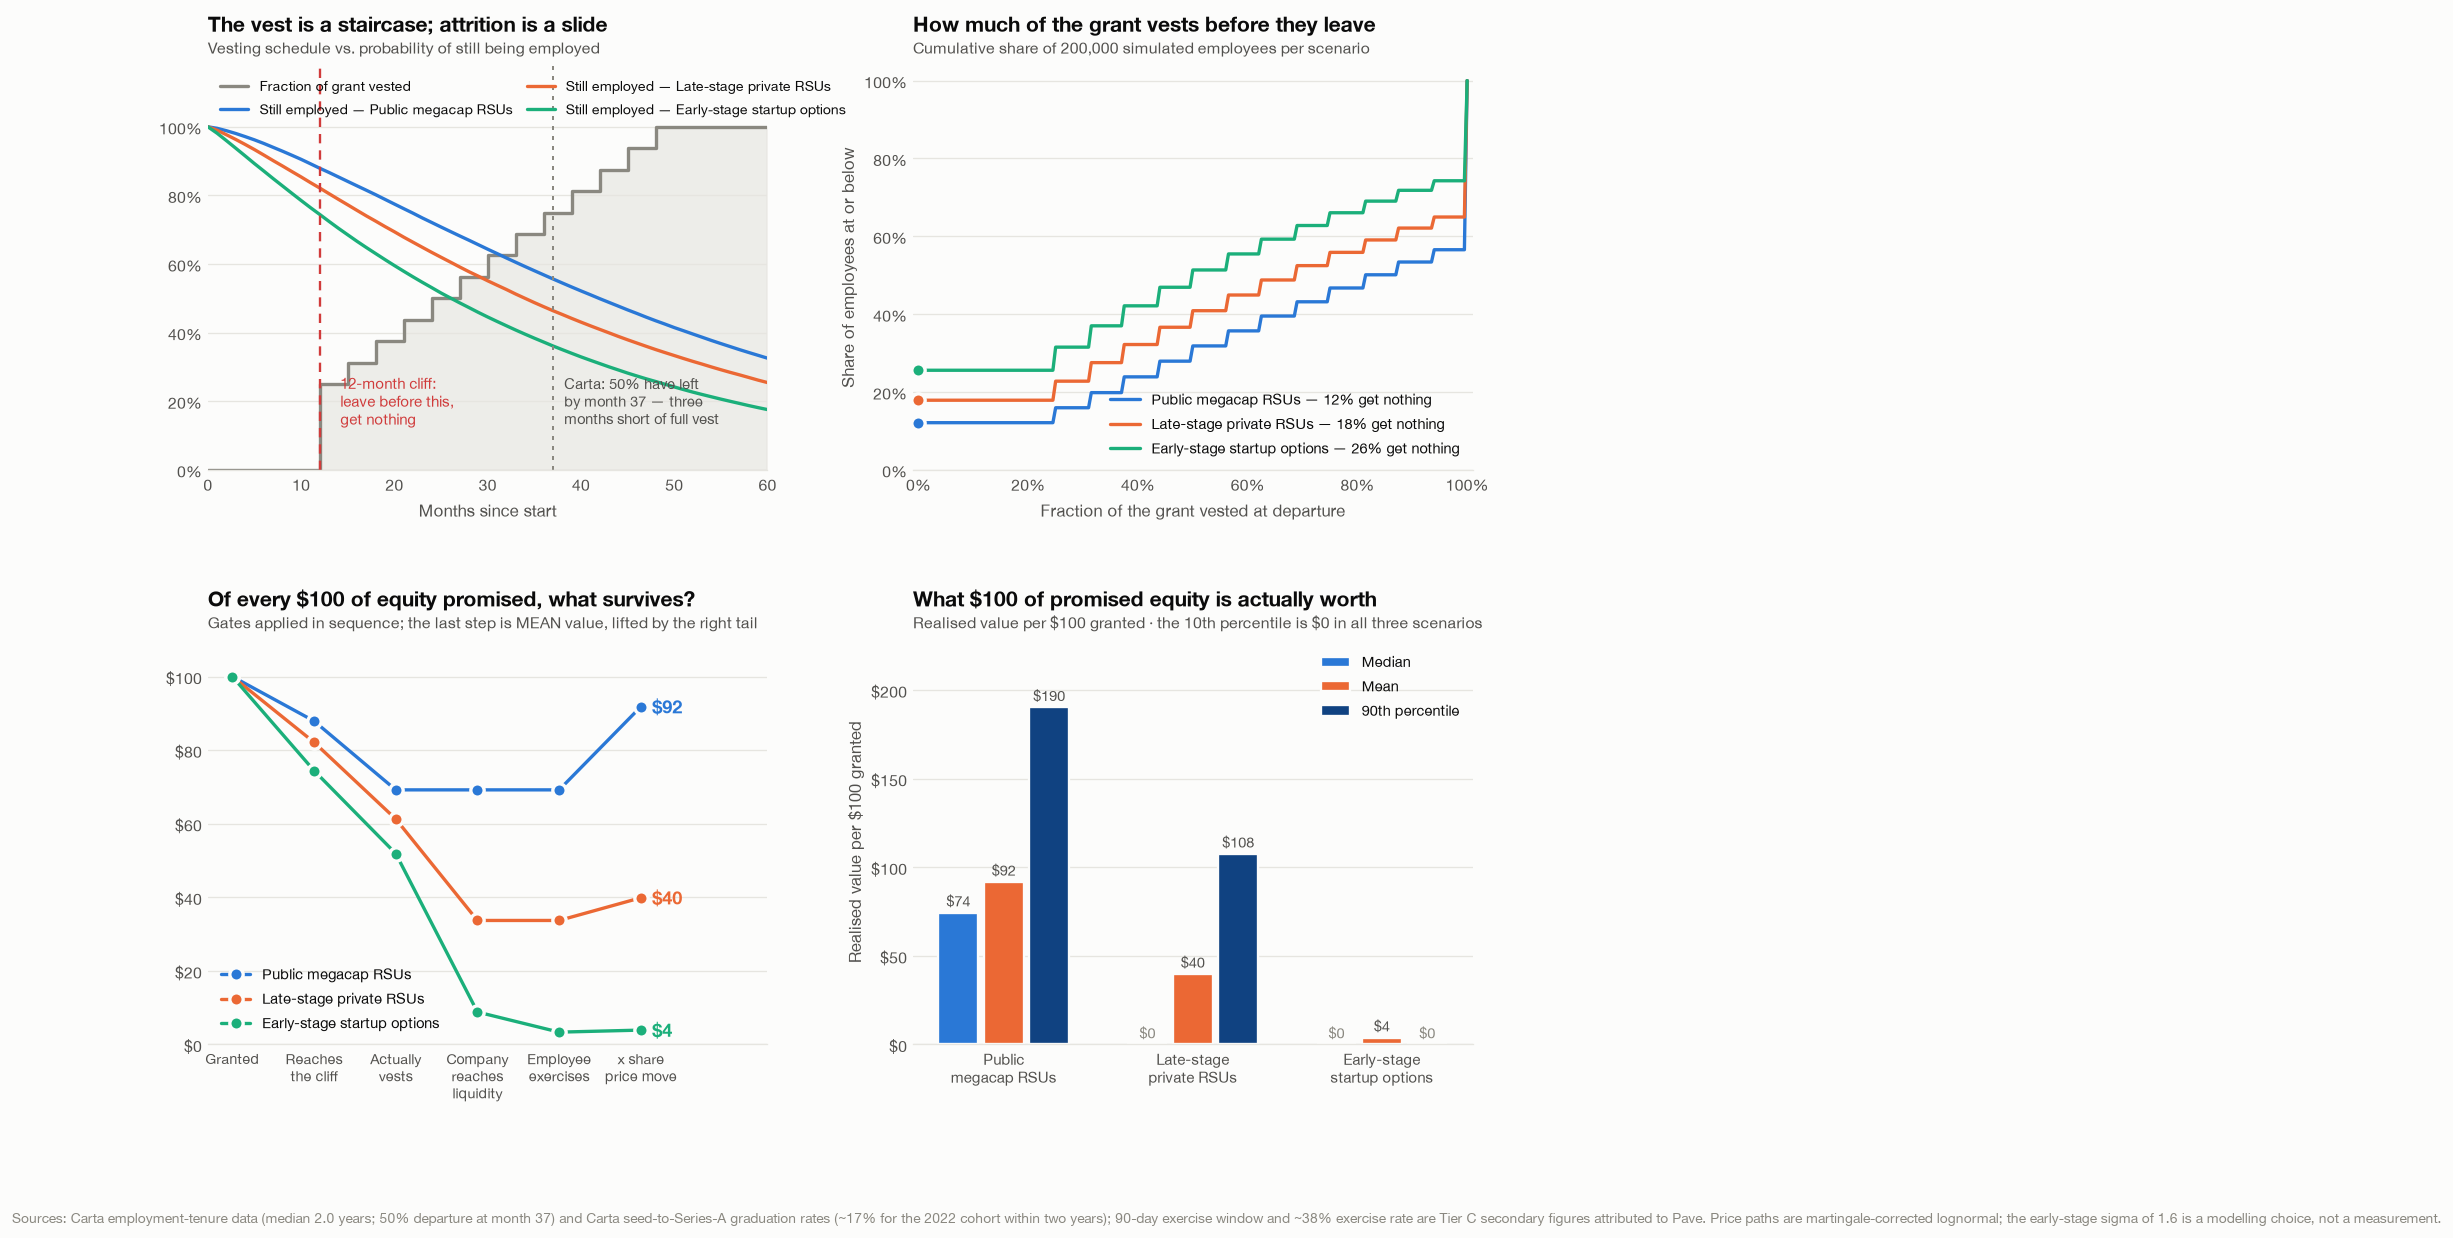

,Reaches the cliff,Fully vests (4 yrs),Mean fraction vested,P(realised value = 0),Median value per $1,Mean value per $1,P90 value per $1
Public megacap RSUs,87.9%,43.5%,69.2%,12.1%,$0.74,$0.92,$1.90
Late-stage private RSUs,82.1%,35.1%,61.3%,55.0%,$0.00,$0.40,$1.08
Early-stage startup options,74.4%,25.7%,51.9%,95.2%,$0.00,$0.04,$0.00



Public megacap RSUs
   88% get past the cliff; on average 69% of the grant vests.
   12% of employees realise NOTHING.
   Median $0.74 vs mean $0.92 per $1 granted — a 1.2x gap.

Late-stage private RSUs
   82% get past the cliff; on average 61% of the grant vests.
   55% of employees realise NOTHING.
   Median $0.00 vs mean $0.40 per $1 granted — the mean is entirely tail.

Early-stage startup options
   74% get past the cliff; on average 52% of the grant vests.
   95% of employees realise NOTHING.
   Median $0.00 vs mean $0.04 per $1 granted — the mean is entirely tail.


In [13]:
fig = plt.figure(figsize=(13.6, 10.6))
gs  = fig.add_gridspec(2, 2, hspace=0.42, wspace=0.26)
ax1, ax2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ax3, ax4 = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])

# --- 1: the vesting staircase vs. the survival curve
months = np.arange(0, 61)
ax1.step(months, vest_fraction(months, **VEST) * 100, where="post",
         color=INK_3, lw=2.0, label="Fraction of grant vested")
ax1.fill_between(months, 0, vest_fraction(months, **VEST) * 100,
                 step="post", color=GRID, alpha=0.65)
for name, s in SIMS.items():
    surv = [(s["tenure"] > m).mean() * 100 for m in months]
    ax1.plot(months, surv, color=SCENARIOS[name]["colour"], label=f"Still employed — {name}")
ax1.axvline(12, color=STATUS["critical"], lw=1.4, ls=(0, (4, 3)))
ax1.text(14.2, 20, "12-month cliff:\nleave before this,\nget nothing",
         color=STATUS["critical"], fontsize=9, va="center")
ax1.axvline(37, color=INK_3, lw=1.2, ls=(0, (2, 3)))
ax1.text(38.2, 20, "Carta: 50% have left\nby month 37 — three\nmonths short of full vest",
         color=INK_2, fontsize=8.8, va="center")
ax1.set_xlim(0, 60); ax1.set_ylim(0, 118)
ax1.set_yticks([0, 20, 40, 60, 80, 100])
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}%"))
frame(ax1, "The vest is a staircase; attrition is a slide",
      "Vesting schedule vs. probability of still being employed",
      xlabel="Months since start")
ax1.legend(loc="upper left", fontsize=8.4, ncols=2, columnspacing=1.0)

# --- 2: distribution of the fraction actually vested
grid = np.linspace(0, 1, 201)
for name, s in SIMS.items():
    cdf = [(s["frac"] <= g).mean() * 100 for g in grid]
    zero = (s["frac"] <= 1e-9).mean() * 100
    ax2.plot(grid * 100, cdf, color=SCENARIOS[name]["colour"],
             label=f"{name} — {zero:.0f}% get nothing")
    ax2.plot([0], [zero], "o", color=SCENARIOS[name]["colour"], ms=8,
             markeredgecolor=SURFACE, markeredgewidth=2)
ax2.set_xlim(-1, 101); ax2.set_ylim(0, 104)
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}%"))
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}%"))
frame(ax2, "How much of the grant vests before they leave",
      "Cumulative share of 200,000 simulated employees per scenario",
      xlabel="Fraction of the grant vested at departure",
      ylabel="Share of employees at or below")
ax2.legend(loc="lower right", fontsize=8.8)

# --- 3: the funnel, $100 of grant -> what survives each gate
gates = ["Granted", "Reaches\nthe cliff", "Actually\nvests", "Company\nreaches\nliquidity",
         "Employee\nexercises", "x share\nprice move"]
for name, s in SIMS.items():
    sc = SCENARIOS[name]
    v = [100.0,
         (s["frac"] > 0).mean() * 100,
         s["frac"].mean() * 100,
         s["frac"].mean() * sc["p_liquid"] * 100,
         s["frac"].mean() * sc["p_liquid"] * (sc["p_exercise"] if sc["exercise_required"] else 1.0) * 100,
         s["realised"].mean() * 100]
    ax3.plot(range(len(gates)), v, "o-", color=sc["colour"], ms=8, label=name,
             markeredgecolor=SURFACE, markeredgewidth=2)
    ax3.text(len(gates) - 1 + 0.14, v[-1], f"${v[-1]:,.0f}",
             color=sc["colour"], fontsize=10.5, fontweight="bold", va="center")
ax3.set_xticks(range(len(gates))); ax3.set_xticklabels(gates, fontsize=8.6)
ax3.set_xlim(-0.3, len(gates) + 0.55); ax3.set_ylim(0, 110)
ax3.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"${v:.0f}"))
frame(ax3, "Of every $100 of equity promised, what survives?",
      "Gates applied in sequence; the last step is MEAN value, lifted by the right tail")
ax3.legend(loc="lower left", fontsize=8.8)

# --- 4: realised value distribution — median vs mean vs the tail
labels = list(SCENARIOS)
xx = np.arange(len(labels))
p50 = [np.percentile(SIMS[n]["realised"], 50) * 100 for n in labels]
p90 = [np.percentile(SIMS[n]["realised"], 90) * 100 for n in labels]
mean = [SIMS[n]["realised"].mean() * 100 for n in labels]
w = 0.24
for i, (vals, lab, c) in enumerate([(p50, "Median", BLUE_RAMP[7]),
                                    (mean, "Mean", SERIES[1]),
                                    (p90, "90th percentile", BLUE_RAMP[11])]):
    bars = ax4.bar(xx + (i - 1) * w, vals, w * 0.88, color=c, label=lab,
                   edgecolor=SURFACE, linewidth=1.4)
    for b, v in zip(bars, vals):
        ax4.text(b.get_x() + b.get_width() / 2, v + 3.5, f"${v:.0f}", ha="center",
                 color=INK_2 if v > 0 else INK_3, fontsize=8.8)
ax4.set_xticks(xx)
ax4.set_xticklabels([l.replace(" ", "\n", 1) for l in labels], fontsize=9)
ax4.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"${v:.0f}"))
ax4.set_ylim(0, max(p90 + mean) * 1.20)
frame(ax4, "What $100 of promised equity is actually worth",
      "Realised value per $100 granted · the 10th percentile is $0 in all three scenarios",
      ylabel="Realised value per $100 granted")
ax4.legend(loc="upper right", ncols=1, fontsize=8.8)

source_note(fig, "Sources: Carta employment-tenure data (median 2.0 years; 50% departure at month 37) and Carta "
                 "seed-to-Series-A graduation rates (~17% for the 2022 cohort within two years); 90-day exercise "
                 "window and ~38% exercise rate are Tier C secondary figures attributed to Pave. Price paths are "
                 "martingale-corrected lognormal; the early-stage sigma of 1.6 is a modelling choice, not a measurement.")
plt.show()

summary = pd.DataFrame({
    n: {"Reaches the cliff": (SIMS[n]["frac"] > 0).mean(),
        "Fully vests (4 yrs)": (SIMS[n]["frac"] >= 0.999).mean(),
        "Mean fraction vested": SIMS[n]["frac"].mean(),
        "P(realised value = 0)": (SIMS[n]["realised"] <= 1e-9).mean(),
        "Median value per $1": np.median(SIMS[n]["realised"]),
        "Mean value per $1": SIMS[n]["realised"].mean(),
        "P90 value per $1": np.percentile(SIMS[n]["realised"], 90)} for n in SCENARIOS}).T
display(summary.style.format({"Reaches the cliff": "{:.1%}", "Fully vests (4 yrs)": "{:.1%}",
                              "Mean fraction vested": "{:.1%}", "P(realised value = 0)": "{:.1%}",
                              "Median value per $1": "${:.2f}", "Mean value per $1": "${:.2f}",
                              "P90 value per $1": "${:.2f}"}))

for n in SCENARIOS:
    s = SIMS[n]
    print(f"\n{n}")
    print(f"   {(s['frac']>0).mean():.0%} get past the cliff; on average {s['frac'].mean():.0%} of the grant vests.")
    print(f"   {(s['realised']<=1e-9).mean():.0%} of employees realise NOTHING.")
    print(f"   Median ${np.median(s['realised']):.2f} vs mean ${s['realised'].mean():.2f} per $1 granted "
          f"— a {s['realised'].mean()/max(np.median(s['realised']),1e-9):,.1f}x gap." if np.median(s['realised']) > 0
          else f"   Median $0.00 vs mean ${s['realised'].mean():.2f} per $1 granted — the mean is entirely tail.")

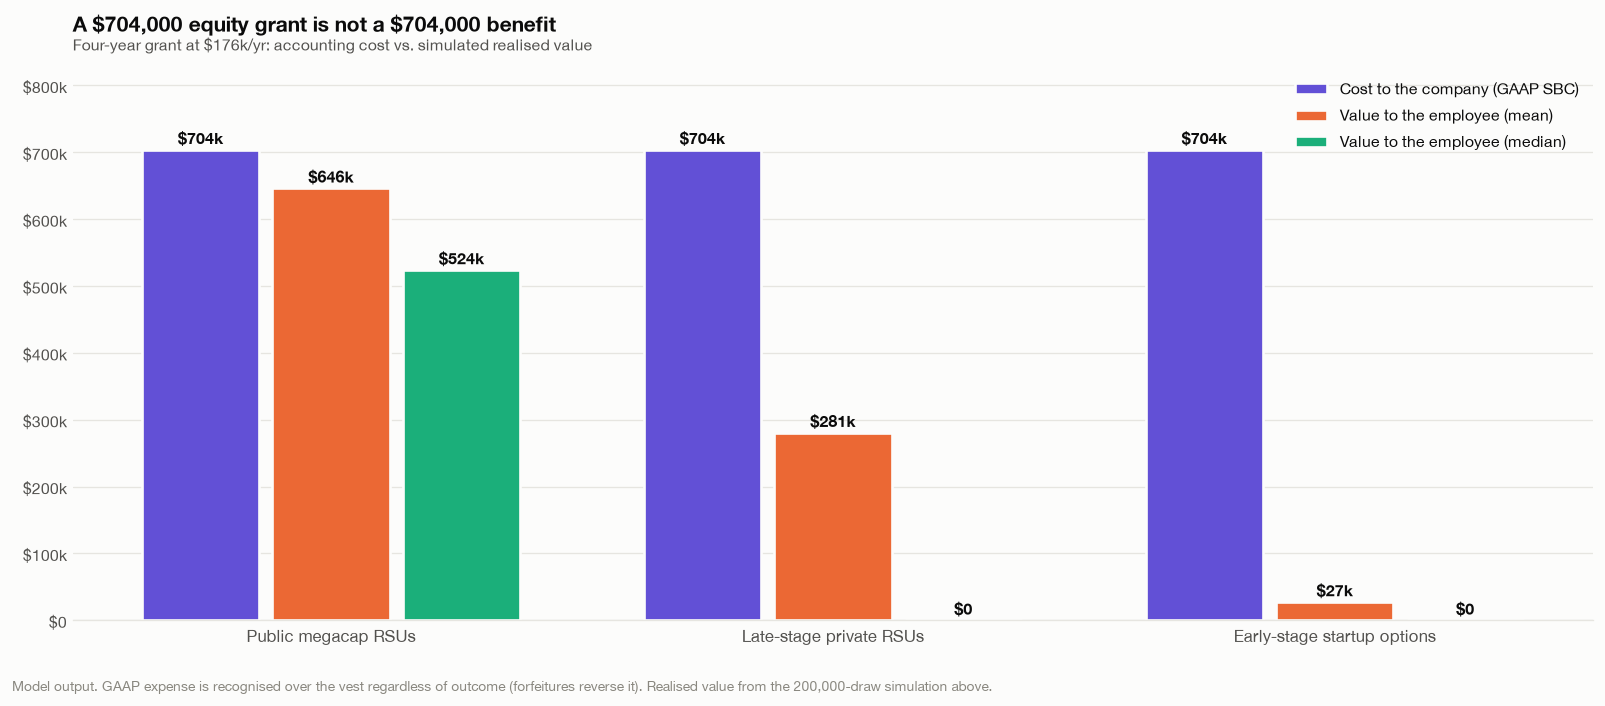

Public megacap RSUs             efficiency:   92% of accounting cost reaches the employee on average,  74% at the median
Late-stage private RSUs         efficiency:   40% of accounting cost reaches the employee on average,   0% at the median
Early-stage startup options     efficiency:    4% of accounting cost reaches the employee on average,   0% at the median

The gap is not waste — it is risk transfer. The employer converts a certain accounting cost
into an uncertain employee benefit, and keeps the forfeitures. Whether that is a good deal for
the employee depends entirely on which row of this chart they are actually in.


In [14]:
# --- Employer cost vs. employee value, side by side -------------------------
GRANT = 704_000       # 4 x $176k annualised — the number on the offer letter
fig, ax = plt.subplots(figsize=(13.4, 5.6))

labels = list(SCENARIOS)
xx = np.arange(len(labels))
cost = np.full(len(labels), GRANT)                       # GAAP expense: the same every time
emp_med  = np.array([np.median(SIMS[n]["realised"]) for n in labels]) * GRANT
emp_mean = np.array([SIMS[n]["realised"].mean() for n in labels]) * GRANT

w = 0.26
b1 = ax.bar(xx - w, cost, w * 0.9, color=SERIES[6], label="Cost to the company (GAAP SBC)",
            edgecolor=SURFACE, linewidth=1.6)
b2 = ax.bar(xx,     emp_mean, w * 0.9, color=SERIES[1], label="Value to the employee (mean)",
            edgecolor=SURFACE, linewidth=1.6)
b3 = ax.bar(xx + w, emp_med,  w * 0.9, color=SERIES[2], label="Value to the employee (median)",
            edgecolor=SURFACE, linewidth=1.6)
for bars in (b1, b2, b3):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + GRANT * 0.012,
                money(b.get_height()), ha="center", color=INK, fontsize=9.4, fontweight="bold")
ax.set_xticks(xx); ax.set_xticklabels(labels, fontsize=10)
ax.set_ylim(0, GRANT * 1.18)
frame(ax, "A $704,000 equity grant is not a $704,000 benefit",
      "Four-year grant at $176k/yr: accounting cost vs. simulated realised value",
      money_y=True)
ax.legend(loc="upper right")
fig.tight_layout()
source_note(fig, "Model output. GAAP expense is recognised over the vest regardless of outcome (forfeitures reverse it). "
                 "Realised value from the 200,000-draw simulation above.")
plt.show()

for i, n in enumerate(labels):
    eff = emp_mean[i] / GRANT
    print(f"{n:30s}  efficiency: {eff:5.0%} of accounting cost reaches the employee on average, "
          f"{emp_med[i]/GRANT:4.0%} at the median")
print("\nThe gap is not waste — it is risk transfer. The employer converts a certain accounting cost")
print("into an uncertain employee benefit, and keeps the forfeitures. Whether that is a good deal for")
print("the employee depends entirely on which row of this chart they are actually in.")

<a id="s10"></a>
## 10 · Q9 — Range of accuracy: how wrong could this be?

A single number like "$375,000" implies a precision this model does not have. Roughly a third of
the inputs are Tier C — practitioner benchmarks with no published error bars. Rather than pretend
otherwise, the uncertainty gets propagated.

**Method.** Every uncertain input gets a distribution instead of a point. **Triangular** where a
plausible low / likely / high is all anyone can honestly state (agency fees, sqft per employee,
cloud spend, workers' comp). **Normal** where a survey publishes a mean over a large sample (health
premiums, the 401(k) match). **Bernoulli** where the input is a policy coin-flip (agency vs.
internal sourcing, work mode). 40,000 draws, then read the percentiles off the result.

**Two bands, because there are two different questions.** This distinction turns out to matter more
than any individual input:

- **Band A — "I know the offer."** The salary is settled; only the loading is uncertain. This is
  what a finance partner is asking when approving a specific req.
- **Band B — "I'm budgeting for a hire."** The level and the negotiated salary are *also* unknown,
  drawn from a plausible Bay Area hiring mix. This is what a founder is asking when planning next
  year's headcount.

A **tornado chart** then isolates which single input moves the answer most — including the two
binary policy choices, which a purely continuous sensitivity analysis would miss entirely.

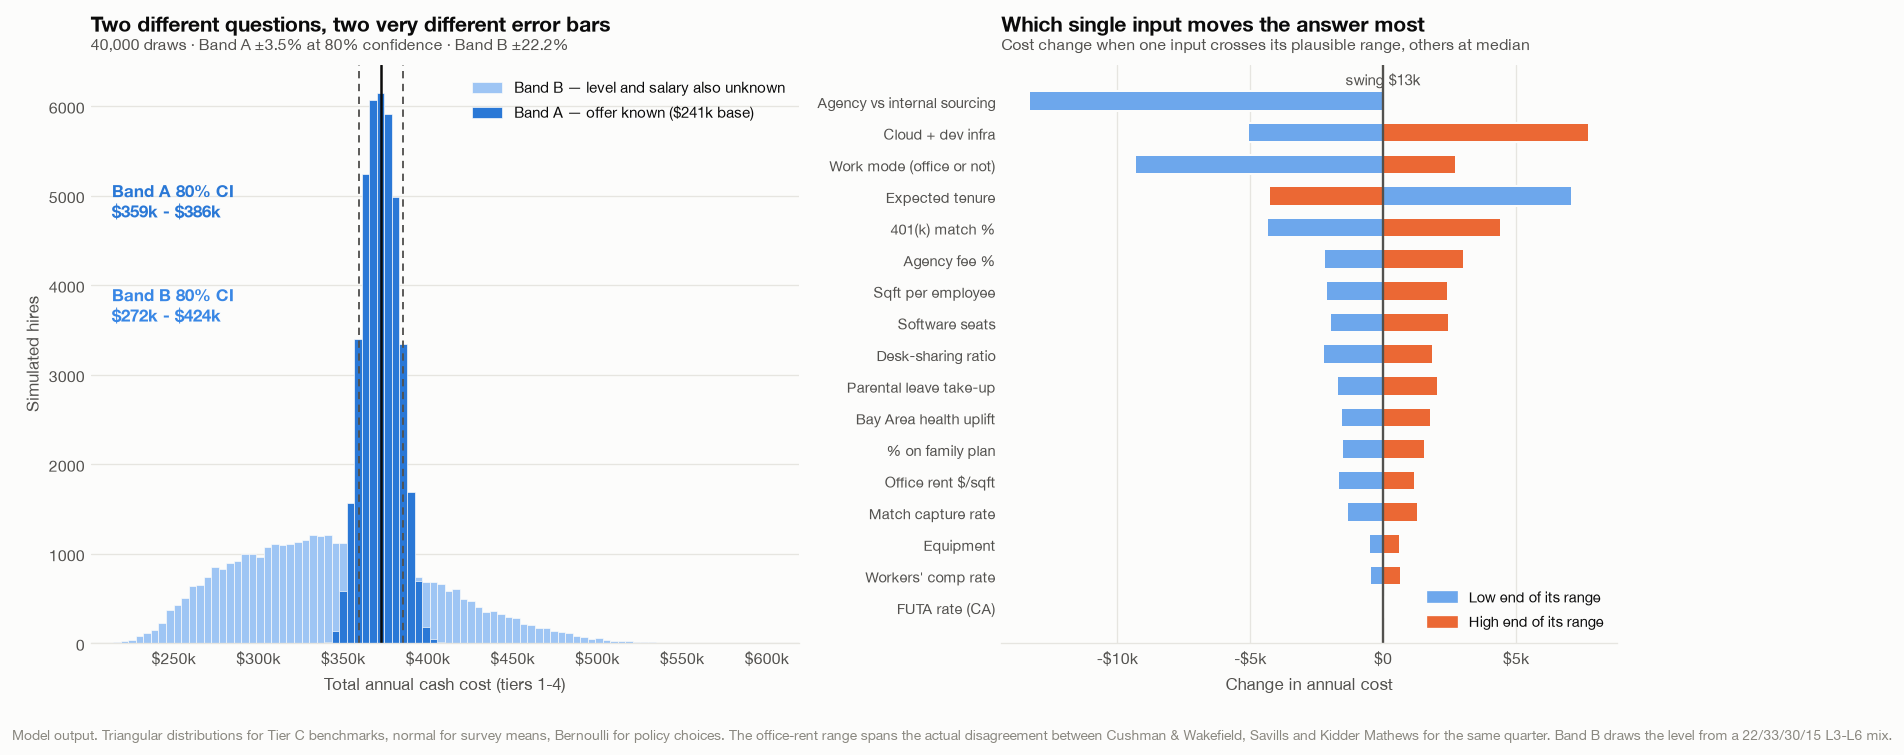

Percentile,Band A — offer known,x base (Band A),Band B — budgeting a hire
P5,"$356,032",1.48x,"$259,380"
P10,"$359,229",1.49x,"$272,311"
P25,"$364,787",1.51x,"$301,451"
Median,"$372,140",1.54x,"$340,687"
P75,"$379,574",1.57x,"$383,734"
P90,"$385,628",1.60x,"$423,652"
P95,"$388,934",1.61x,"$447,643"


RANGE OF ACCURACY
--------------------------------------------------------------------------------
Band A — the offer is already known ($241k base):
    median $372,140    80% CI $359,229 - $385,628   (±3.5%)
                          90% CI $356,032 - $388,934   (±4.4%)

Band B — budgeting for a hire whose level is not yet fixed:
    median $340,687    80% CI $272,311 - $423,652   (±22.2%)

The finding: once the salary is settled, the loading is predictable to about ±4%.
Before it is settled, the honest band is 6x wider. The dominant uncertainty in
'what will this hire cost' is not the benefits model — it is the salary itself.

Biggest single input:  Agency vs internal sourcing  (swing $13,309)
Second:                Cloud + dev infra  (swing $12,811)
Third:                 Work mode (office or not)  (swing $12,051)
Smallest:              FUTA rate (CA)  (swing $101) — not worth measuring.


In [15]:
N_MC = 40_000
mc = np.random.default_rng(2026)

def tri(lo, mode, hi, n=N_MC, rng=None):
    return (rng or mc).triangular(lo, mode, hi, n)

def draw_inputs(n, rng):
    "Every uncertain input, declared once with its distribution."
    return dict(
        agency_fee_pct      = tri(0.18, 0.22, 0.30, n, rng),
        expected_tenure_yrs = tri(2.0, 3.5, 6.0, n, rng),
        rent_psf            = tri(49.29, 70.31, 79.03, n, rng),   # the publishers' own disagreement
        sqft_per_employee   = tri(120, 175, 250, n, rng),
        desk_ratio          = tri(0.5, 0.8, 1.0, n, rng),
        bay_area_uplift     = tri(1.00, 1.15, 1.35, n, rng),
        family_tier_share   = tri(0.30, 0.45, 0.60, n, rng),
        match_promised_pct  = np.clip(rng.normal(0.047, 0.012, n), 0.0, 0.10),
        match_capture_rate  = tri(0.65, 0.80, 0.95, n, rng),
        wc_rate             = tri(0.002, 0.004, 0.008, n, rng),
        futa_rate           = tri(0.006, 0.018, 0.027, n, rng),   # 2026 CA reduction unsettled
        software_seats      = tri(2_500, 5_000, 9_000, n, rng),
        cloud_dev_infra     = tri(1_500, 6_000, 20_000, n, rng),
        equipment           = tri(1_100, 1_733, 2_800, n, rng),
        parental_take_up    = tri(0.04, 0.08, 0.14, n, rng),
        agency_sourced      = (rng.random(n) < 0.55).astype(float),
        onsite_draw         = rng.random(n),
    )

def mc_cost(u, base):
    "Vectorised total cash cost (tiers 1-4) across an array of draws."
    base = np.asarray(base, float)
    bonus = base * 0.15
    equity = base * 0.73
    fica = base + bonus + equity
    tax = (0.062 * np.minimum(fica, 184_500) + 0.0145 * fica
           + u["futa_rate"] * 7_000 + 0.034 * 7_000 + 0.001 * 7_000
           + u["wc_rate"] * (base + bonus))

    single, family = 7_885 * 1.05, 20_143 * 1.06
    med = ((1 - u["family_tier_share"]) * single + u["family_tier_share"] * family) * u["bay_area_uplift"]
    ben = (med + 850 + 170 + 250 + 500 + 700 + 600 + 1_500 + 900 + 500
           + np.minimum(base + bonus, 360_000) * u["match_promised_pct"] * u["match_capture_rate"]
           + base * (12 / 52) * u["parental_take_up"]
           + base * 0.006)

    recr = np.where(u["agency_sourced"] > 0.5,
                    u["agency_fee_pct"] * base, 5_475) / u["expected_tenure_yrs"]
    desk = np.where(u["onsite_draw"] < 0.25, 1.0,
                    np.where(u["onsite_draw"] < 0.85, u["desk_ratio"], 0.0))
    ovh = (recr + u["rent_psf"] * u["sqft_per_employee"] * desk + u["equipment"]
           + u["software_seats"] + u["cloud_dev_infra"] + 800 + 900 + 400)
    return base + bonus + tax + ben + ovh

U = draw_inputs(N_MC, mc)

# Band A — the offer is known.
tot_A = mc_cost(U, np.full(N_MC, 241_000.0))

# Band B — the level and the negotiated salary are unknown too.
LEVEL_BASE = np.array([166_000, 204_000, 241_000, 283_000], float)
LEVEL_MIX  = np.array([0.22, 0.33, 0.30, 0.15])                 # plausible Bay Area hiring mix
base_B = LEVEL_BASE[mc.choice(len(LEVEL_BASE), N_MC, p=LEVEL_MIX)] * np.exp(mc.normal(0, 0.10, N_MC))
tot_B = mc_cost(U, base_B)

pA = np.percentile(tot_A, [5, 10, 25, 50, 75, 90, 95])
pB = np.percentile(tot_B, [5, 10, 25, 50, 75, 90, 95])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 6.0),
                               gridspec_kw={"width_ratios": [1.15, 1]})

bins = np.linspace(min(tot_A.min(), tot_B.min()), max(tot_A.max(), tot_B.max()), 95)
ax1.hist(tot_B, bins=bins, color=BLUE_RAMP[2], edgecolor=SURFACE, linewidth=0.4,
         label="Band B — level and salary also unknown")
ax1.hist(tot_A, bins=bins, color=SERIES[0], edgecolor=SURFACE, linewidth=0.4,
         label="Band A — offer known ($241k base)")
for v, is_med in [(pA[1], False), (pA[3], True), (pA[5], False)]:
    ax1.axvline(v, color=INK if is_med else INK_2, lw=1.5 if is_med else 1.1,
                ls="-" if is_med else (0, (4, 3)))
ax1.set_xlim(bins[0], bins[-1])
frame(ax1, "Two different questions, two very different error bars",
      f"40,000 draws · Band A ±{(pA[5]-pA[1])/2/pA[3]:.1%} at 80% confidence · "
      f"Band B ±{(pB[5]-pB[1])/2/pB[3]:.1%}",
      xlabel="Total annual cash cost (tiers 1-4)", ylabel="Simulated hires", money_x=True)
ax1.legend(loc="upper right", fontsize=9)
ax1.text(0.03, 0.80, f"Band A 80% CI\n{money(pA[1])} - {money(pA[5])}",
         transform=ax1.transAxes, color=SERIES[0], fontsize=10, fontweight="bold",
         va="top", ha="left")
ax1.text(0.03, 0.62, f"Band B 80% CI\n{money(pB[1])} - {money(pB[5])}",
         transform=ax1.transAxes, color=BLUE_RAMP[6], fontsize=10, fontweight="bold",
         va="top", ha="left")

# --- tornado: one input at a time, all others held at their median ----------
PRETTY = {"agency_sourced": "Agency vs internal sourcing", "cloud_dev_infra": "Cloud + dev infra",
          "expected_tenure_yrs": "Expected tenure", "onsite_draw": "Work mode (office or not)",
          "agency_fee_pct": "Agency fee %", "bay_area_uplift": "Bay Area health uplift",
          "sqft_per_employee": "Sqft per employee", "software_seats": "Software seats",
          "match_promised_pct": "401(k) match %", "rent_psf": "Office rent $/sqft",
          "family_tier_share": "% on family plan", "match_capture_rate": "Match capture rate",
          "desk_ratio": "Desk-sharing ratio", "parental_take_up": "Parental leave take-up",
          "equipment": "Equipment", "futa_rate": "FUTA rate (CA)", "wc_rate": "Workers' comp rate"}
BINARY_ENDS = {"agency_sourced": (0.0, 1.0), "onsite_draw": (0.95, 0.10)}  # (cheap end, costly end)

med_u = {k: np.array([np.median(v)]) for k, v in U.items()}
centre = mc_cost(med_u, np.array([241_000.0]))[0]

tor = []
for key, label in PRETTY.items():
    lo_v, hi_v = BINARY_ENDS.get(key, tuple(np.quantile(U[key], [0.05, 0.95])))
    ends = []
    for val in (lo_v, hi_v):
        d = dict(med_u); d[key] = np.array([val])
        ends.append(mc_cost(d, np.array([241_000.0]))[0])
    tor.append((label, ends[0] - centre, ends[1] - centre, abs(ends[1] - ends[0])))
tor.sort(key=lambda r: r[3])

for i, (_nm, lo_d, hi_d, _sw) in enumerate(tor):
    ax2.barh(i, lo_d, 0.62, color=BLUE_RAMP[4], edgecolor=SURFACE, linewidth=1.2)
    ax2.barh(i, hi_d, 0.62, color=SERIES[1], edgecolor=SURFACE, linewidth=1.2)
ax2.axvline(0, color=INK_2, lw=1.4)
ax2.set_yticks(range(len(tor))); ax2.set_yticklabels([t[0] for t in tor], fontsize=8.8)
ax2.xaxis.set_major_formatter(MONEY)
ax2.text(tor[-1][2] * 0.6, len(tor) - 1 + 0.5, f"swing {money(tor[-1][3])}",
         color=INK_2, fontsize=9, ha="center")
frame(ax2, "Which single input moves the answer most",
      "Cost change when one input crosses its plausible range, others at median",
      xlabel="Change in annual cost", ygrid=False, xgrid=True)
ax2.add_patch(Rectangle((0, 0), 0, 0, color=BLUE_RAMP[4], label="Low end of its range"))
ax2.add_patch(Rectangle((0, 0), 0, 0, color=SERIES[1], label="High end of its range"))
ax2.legend(loc="lower right", fontsize=8.8)

fig.tight_layout()
source_note(fig, "Model output. Triangular distributions for Tier C benchmarks, normal for survey means, Bernoulli for "
                 "policy choices. The office-rent range spans the actual disagreement between Cushman & Wakefield, "
                 "Savills and Kidder Mathews for the same quarter. Band B draws the level from a 22/33/30/15 L3-L6 mix.")
plt.show()

band = pd.DataFrame({"Percentile": ["P5", "P10", "P25", "Median", "P75", "P90", "P95"],
                     "Band A — offer known": pA, "x base (Band A)": pA / 241_000,
                     "Band B — budgeting a hire": pB})
display(band.style.format({"Band A — offer known": dollars,
                           "Band B — budgeting a hire": dollars,
                           "x base (Band A)": "{:.2f}x"}).hide(axis="index"))

print("RANGE OF ACCURACY")
print("-" * 80)
print("Band A — the offer is already known ($241k base):")
print(f"    median {dollars(pA[3])}    80% CI {dollars(pA[1])} - {dollars(pA[5])}   "
      f"(±{(pA[5]-pA[1])/2/pA[3]:.1%})")
print(f"                          90% CI {dollars(pA[0])} - {dollars(pA[6])}   "
      f"(±{(pA[6]-pA[0])/2/pA[3]:.1%})")
print("\nBand B — budgeting for a hire whose level is not yet fixed:")
print(f"    median {dollars(pB[3])}    80% CI {dollars(pB[1])} - {dollars(pB[5])}   "
      f"(±{(pB[5]-pB[1])/2/pB[3]:.1%})")
print(f"\nThe finding: once the salary is settled, the loading is predictable to about "
      f"±{(pA[5]-pA[1])/2/pA[3]:.0%}.")
print(f"Before it is settled, the honest band is {(pB[5]-pB[1])/(pA[5]-pA[1]):.0f}x wider. The dominant "
      f"uncertainty in\n'what will this hire cost' is not the benefits model — it is the salary itself.")
print(f"\nBiggest single input:  {tor[-1][0]}  (swing {dollars(tor[-1][3])})")
print(f"Second:                {tor[-2][0]}  (swing {dollars(tor[-2][3])})")
print(f"Third:                 {tor[-3][0]}  (swing {dollars(tor[-3][3])})")
print(f"Smallest:              {tor[0][0]}  (swing {dollars(tor[0][3])}) — not worth measuring.")

<a id="s11"></a>
## 11 · Q10 — How much revenue does this person have to generate?

Cost is only half an argument. The other half is what the business needs back, and the public
filings give a hard benchmark: at Alphabet, Meta and NVIDIA, **revenue per employee** is a number
you can read straight off a 10-K.

The breakeven below answers: *at a given gross margin, what revenue must this hire be associated
with to pay for themselves?* It is deliberately a crude unit-economics question — engineers do not
have attributable revenue — but it reframes "is $375k a lot?" into "is this person plausibly worth
$X of revenue at our margin?", which is the question a CFO is actually asking.

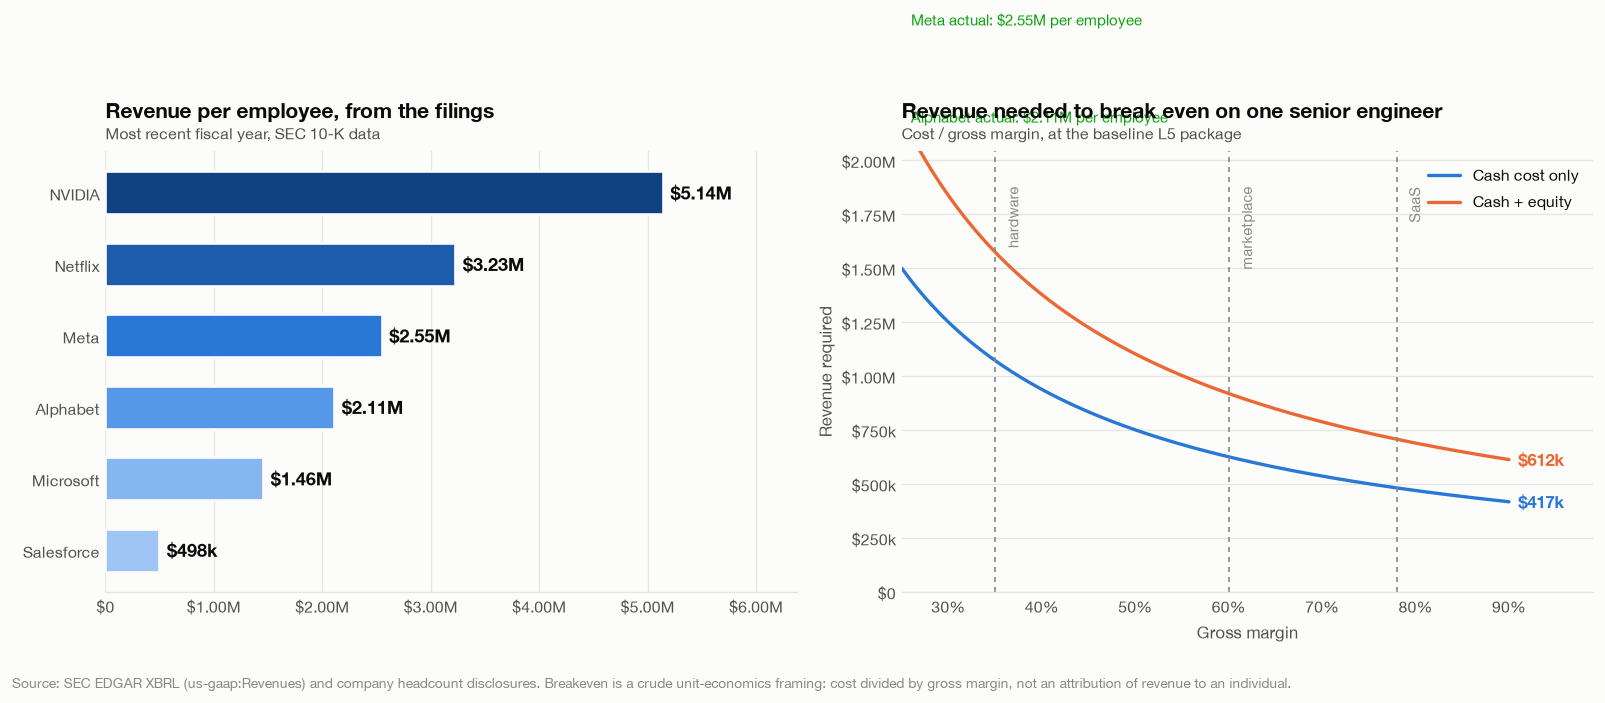

Gross margin,Revenue needed (cash cost),Revenue needed (incl. equity)
35%,"$1,071,533","$1,574,390"
50%,"$750,073","$1,102,073"
65%,"$576,979","$847,748"
80%,"$468,795","$688,795"
90%,"$416,707","$612,263"



At a typical 78% SaaS gross margin, one senior engineer must be associated with $706,457 of revenue to break even fully loaded.
Alphabet runs at $2,111,079 per employee; NVIDIA $5,141,381; Salesforce $498,236.
Spread between the most and least productive filer here: 10.3x.
Fully-loaded cost per head varies by well under 2x. That asymmetry is why the most productive
companies can outbid everyone on compensation and still win on margin — and why a company at
Salesforce's revenue per head cannot simply copy Google's offer.


In [16]:
rev = pd.DataFrame([
    dict(Company=c, Rev_per_emp=d["revenue_usd"] / d["employees"], FY=d["fiscal_year"].split(" ")[0])
    for c, d in EQ.items()]).sort_values("Rev_per_emp", ascending=False).reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 5.8))

cols = [BLUE_RAMP[11 - min(i * 2, 9)] for i in range(len(rev))]
ax1.barh(rev.Company, rev.Rev_per_emp, 0.6, color=cols, edgecolor=SURFACE, linewidth=1.6)
for i, v in enumerate(rev.Rev_per_emp):
    ax1.text(v + 70_000, i, money(v), va="center", color=INK, fontsize=10.5, fontweight="bold")
ax1.invert_yaxis(); ax1.set_xlim(0, rev.Rev_per_emp.max() * 1.24)
frame(ax1, "Revenue per employee, from the filings",
      "Most recent fiscal year, SEC 10-K data",
      money_x=True, ygrid=False, xgrid=True)

margins = np.linspace(0.25, 0.90, 200)
for cost_v, lab, c in [(s0["cash"], "Cash cost only", SERIES[0]),
                       (s0["total"], "Cash + equity", SERIES[1])]:
    ax2.plot(margins * 100, cost_v / margins, color=c, label=lab)
    ax2.text(91, cost_v / 0.90, money(cost_v / 0.90), color=c, fontsize=10,
             fontweight="bold", va="center")
for m, lab in [(0.35, "hardware"), (0.60, "marketplace"), (0.78, "SaaS")]:
    ax2.axvline(m * 100, color=INK_3, lw=1.0, ls=(0, (3, 3)))
    ax2.text(m * 100 + 1, s0["total"] / 0.27 * 0.92, lab, color=INK_3, fontsize=8.8,
             rotation=90, va="top")
for co in ("Alphabet", "Meta"):
    v = rev.loc[rev.Company == co, "Rev_per_emp"].iloc[0]
    ax2.axhline(v, color=STATUS["good"], lw=1.1, ls=(0, (5, 4)))
    ax2.text(26, v * 1.03, f"{co} actual: {money(v)} per employee", color=STATUS["good"], fontsize=9)
ax2.set_xlim(25, 99); ax2.set_ylim(0, s0["total"] / 0.27)
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}%"))
frame(ax2, "Revenue needed to break even on one senior engineer",
      "Cost / gross margin, at the baseline L5 package",
      xlabel="Gross margin", ylabel="Revenue required", money_y=True)
ax2.legend(loc="upper right")

fig.tight_layout()
source_note(fig, "Source: SEC EDGAR XBRL (us-gaap:Revenues) and company headcount disclosures. Breakeven is a crude "
                 "unit-economics framing: cost divided by gross margin, not an attribution of revenue to an individual.")
plt.show()

be = pd.DataFrame({"Gross margin": [f"{m:.0%}" for m in (0.35, 0.50, 0.65, 0.80, 0.90)],
                   "Revenue needed (cash cost)": [s0["cash"] / m for m in (0.35, 0.50, 0.65, 0.80, 0.90)],
                   "Revenue needed (incl. equity)": [s0["total"] / m for m in (0.35, 0.50, 0.65, 0.80, 0.90)]})
display(be.style.format({c: dollars for c in be.columns[1:]}).hide(axis="index"))

print(f"\nAt a typical 78% SaaS gross margin, one senior engineer must be associated with "
      f"{dollars(s0['total']/0.78)} of revenue to break even fully loaded.")
print(f"Alphabet runs at {dollars(rev.loc[rev.Company=='Alphabet','Rev_per_emp'].iloc[0])} per employee; "
      f"NVIDIA {dollars(rev.loc[rev.Company=='NVIDIA','Rev_per_emp'].iloc[0])}; "
      f"Salesforce {dollars(rev.loc[rev.Company=='Salesforce','Rev_per_emp'].iloc[0])}.")
print(f"Spread between the most and least productive filer here: {rev.Rev_per_emp.max()/rev.Rev_per_emp.min():.1f}x.")
print("Fully-loaded cost per head varies by well under 2x. That asymmetry is why the most productive")
print("companies can outbid everyone on compensation and still win on margin — and why a company at")
print("Salesforce's revenue per head cannot simply copy Google's offer.")

<a id="s12"></a>
## 12 · Q11 — The cost of them leaving (and of them not working yet)

Two costs that never appear in a compensation budget but dominate the economics of a mis-hire.

**Ramp.** A mid-to-senior engineer in a real codebase takes roughly six months to reach full
productivity. That is not a soft cost: it is six months of fully-loaded cost against a fraction of
the output, plus the senior engineers' time spent onboarding them.

**Replacement.** Practitioner benchmarks put the cost of replacing a technical employee at 0.5× to
2.0× salary — recruiting again, the vacancy, the new person's ramp, and the drag on the team.

The chart below combines them: **the first year of any hire is the expensive one**, and a hire who
leaves at 18 months never repays it.

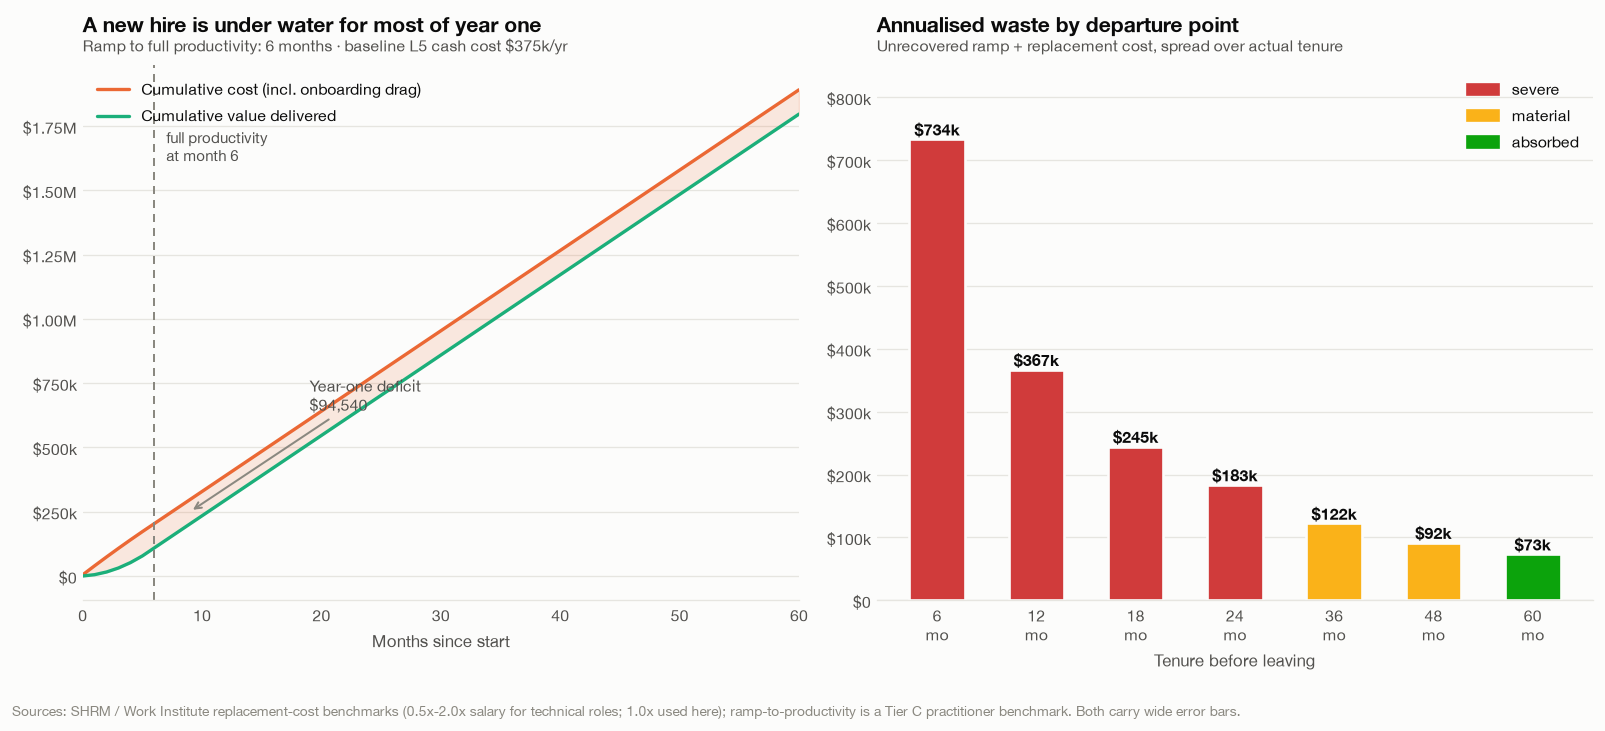

Year-one deficit on a single senior hire: $94,540 before they have paid for their ramp.
A hire who leaves at 18 months costs $244,529 per year of tenure in pure waste.
A hire who stays 4 years costs $91,698 per year of tenure — the same person, 2.7x cheaper.

For scale, the entire default benefits package costs $38,572 a year.
The 18-month departure destroys 5.9 years' worth of it.
That is the retention argument in one line, and it is the one place in this analysis where
the finance answer and the humane answer point in the same direction.


In [17]:
T = SRC["turnover"]
ramp_months = T["ramp_to_full_productivity_months"]["default"]          # 6
annual_cost = s0["cash"]
monthly = annual_cost / 12

months = np.arange(0, 61)
productivity = np.clip(months / ramp_months, 0, 1)
onboard_drag = monthly * 0.15 * np.clip(ramp_months - months, 0, ramp_months) / ramp_months
cum_cost_full = monthly * months + np.cumsum(onboard_drag)
cum_value = np.cumsum(productivity) * monthly

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 5.8))

ax1.plot(months, cum_cost_full, color=SERIES[1], label="Cumulative cost (incl. onboarding drag)")
ax1.plot(months, cum_value, color=SERIES[2], label="Cumulative value delivered")
ax1.fill_between(months, cum_value, cum_cost_full, where=cum_cost_full > cum_value,
                 color=SERIES[1], alpha=0.14)
ax1.axvline(ramp_months, color=INK_3, lw=1.2, ls=(0, (4, 3)))
ax1.text(ramp_months + 1, cum_cost_full[-1] * 0.92, f"full productivity\nat month {ramp_months}",
         color=INK_2, fontsize=9, va="top")
gap = cum_cost_full[12] - cum_value[12]
ax1.annotate(f"Year-one deficit\n{dollars(gap)}", xy=(9, (cum_cost_full[9] + cum_value[9]) / 2),
             xytext=(19, cum_cost_full[-1] * 0.34), color=INK_2, fontsize=9.6,
             arrowprops=dict(arrowstyle="->", color=INK_3, lw=1.2))
ax1.set_xlim(0, 60)
frame(ax1, "A new hire is under water for most of year one",
      f"Ramp to full productivity: {ramp_months} months · baseline L5 cash cost {money(annual_cost)}/yr",
      xlabel="Months since start", money_y=True)
ax1.legend(loc="upper left")

tenures = np.array([6, 12, 18, 24, 36, 48, 60])
repl = 241_000 * T["replacement_cost_pct_of_salary"]["default_technical"]
lost = []
for t in tenures:
    c = monthly * t + np.sum(onboard_drag[:t])
    v = np.sum(productivity[:t]) * monthly
    lost.append((c - v + repl) / (t / 12))
cols = [STATUS["critical"] if l > 180_000 else (STATUS["warning"] if l > 90_000 else STATUS["good"])
        for l in lost]
ax2.bar(np.arange(len(tenures)), lost, 0.56, color=cols, edgecolor=SURFACE, linewidth=1.6)
for i, l in enumerate(lost):
    ax2.text(i, l + 6_000, money(l), ha="center", color=INK, fontsize=9.8, fontweight="bold")
ax2.set_xticks(np.arange(len(tenures)))
ax2.set_xticklabels([f"{t}\nmo" for t in tenures])
ax2.set_ylim(0, max(lost) * 1.16)
frame(ax2, "Annualised waste by departure point",
      "Unrecovered ramp + replacement cost, spread over actual tenure",
      xlabel="Tenure before leaving", money_y=True)
for c, lab in [(STATUS["critical"], "severe"), (STATUS["warning"], "material"),
               (STATUS["good"], "absorbed")]:
    ax2.add_patch(Rectangle((0, 0), 0, 0, color=c, label=lab))
ax2.legend(loc="upper right")

fig.tight_layout()
source_note(fig, "Sources: SHRM / Work Institute replacement-cost benchmarks (0.5x-2.0x salary for technical roles; "
                 "1.0x used here); ramp-to-productivity is a Tier C practitioner benchmark. Both carry wide error bars.")
plt.show()

ben_cost = s0["tiers"]["3 · Benefits"]
print(f"Year-one deficit on a single senior hire: {dollars(gap)} before they have paid for their ramp.")
print(f"A hire who leaves at 18 months costs {dollars(lost[2])} per year of tenure in pure waste.")
print(f"A hire who stays 4 years costs {dollars(lost[5])} per year of tenure — the same person, "
      f"{lost[2]/lost[5]:.1f}x cheaper.")
print(f"\nFor scale, the entire default benefits package costs {dollars(ben_cost)} a year.")
print(f"The 18-month departure destroys {(lost[2]-lost[5])*1.5/ben_cost:.1f} years' worth of it.")
print("That is the retention argument in one line, and it is the one place in this analysis where")
print("the finance answer and the humane answer point in the same direction.")

---

<a id="concl"></a>
## Conclusions

**1 · The fully-loaded multiple is ~1.56× base salary in cash, ~2.29× including equity — and it is
not a constant.** For a $241k L5 senior engineer in the Bay Area the model lands at **$375k of cash
cost** and **$551k including the GAAP equity expense**: $134k of cash that never appears in the
offer letter. The multiple *falls* as salary rises — 1.70× at $150k, 1.56× at $241k and 1.45×
at $400k. A flat 1.4× rule of thumb over-costs junior hires and under-costs senior ones.

**2 · Employer payroll tax is regressive and nearly flat in dollars above $185k.** Social Security
stops at $184,500. California SUI and ETT stop at **$7,000 of wages** — $245 in total, identical
for a new grad and a Distinguished Engineer. The only uncapped employer tax is Medicare at 1.45%,
which is also why **RSUs cost real cash**: employer FICA on a $176k annual vest is a cash bill
arriving on top of a non-cash benefit, and it is in almost nobody's model.

**3 · Recruiting is the single biggest overhead line — bigger than health insurance.** A 22% agency
fee on a $241k base is $53,020, about $15k a year amortised over a 3.5-year tenure, against ~$16k
for medical. The *channel choice itself* — agency or internal — is also the largest single swing in
the sensitivity analysis. Before refining anything else in this model, measure your own cost per
hire.

**4 · Benefits are flat-dollar and therefore regressive too.** The default package costs ~$38.6k
regardless of level: 16% of a new grad's base, 13% of a senior's. Medical and the 401(k) match are
**69%** of it; every other benefit combined is smaller than medical alone. The design corollary:
the perks that *feel* generous are cheap, and the two that don't feel like perks at all are where
the money actually goes.

**5 · A $704,000 equity grant is not a $704,000 benefit.** From 200,000 simulated employees per
scenario:

| Scenario | Past the cliff | Fully vests | **Realise nothing** | Median per $1 | Mean per $1 |
|---|---|---|---|---|---|
| Public megacap RSUs | 88% | 44% | 12% | **$0.74** | $0.92 |
| Late-stage private RSUs | 82% | 35% | **55%** | **$0.00** | $0.40 |
| Early-stage startup options | 74% | 26% | **95%** | **$0.00** | $0.04 |

For early-stage options the **median outcome is zero** while the mean is positive — the entire
expected value lives in a thin right tail. The gap between the company's certain accounting cost
and the employee's uncertain benefit is not waste; it is **risk transfer**, and the employee holds
the risk. Quoting a candidate the face value of a grant — or even its expected value — without the
median and the probability of zero is an incomplete disclosure.

**6 · Carta's attrition curve and a four-year vest are almost perfectly adversarial.** 50% of
startup employees have left by **month 37** — three months short of full vesting. Only ~26% of
early-stage employees in the simulation ever reach the end of the schedule. That is not an
accident; it is what a cliff-and-ladder schedule is built to do.

**7 · The honest error bar depends on which question you asked.** Once the salary is settled, the
loading is predictable to roughly **±4% at 80% confidence** (~$359k–$386k). Before it is settled —
budgeting for a hire whose level isn't fixed — the band is about **six times wider**. The dominant
uncertainty in "what will this hire cost" is not the benefits model; it is the salary, and after
that the recruiting channel. Workers' comp, FUTA and the exact desk ratio are noise, and anyone
quoting a fully-loaded cost to the dollar is quoting noise too.

**8 · The first year is the expensive one, and that is where the retention argument lives.** A new
senior hire is under water by roughly **$95k** through month 12 after ramp and onboarding drag. A
hire who leaves at 18 months burns ~$245k per year of tenure; one who stays four years burns ~$92k.
Same person, 2.7× cheaper. Benefits that look expensive per head are usually cheaper than the
attrition they prevent.

**9 · Cost per head varies far less than output per head.** Revenue per employee across these
filers spans about 10× (Salesforce to NVIDIA). Fully-loaded cost per head varies by well under 2×.
That asymmetry is the entire reason the most productive companies can outbid everyone on
compensation and still come out ahead on margin — and the reason a company with Salesforce-like
revenue per head cannot simply copy Google's offer.

---

### What this model is not

- **Not a tax or legal opinion.** The 2026 California FUTA credit reduction is genuinely unsettled
  until the IRS notice lands in November 2026; your actual SUI rate is experience-rated and will not
  be the 3.4% new-employer rate. Confirm with EDD and your payroll provider.
- **Not a market survey.** levels.fyi is self-reported and skews toward large public employers and
  toward people pleased enough with an offer to post it. The Bay Area medians here are the upper
  half of the real market.
- **Not a prediction about any individual.** The vesting simulation is a population model. It says
  nothing about whether *your* grant will be worth something, and the early-stage volatility
  parameter is a modelling choice, not a measurement.
- **Not auditable as GAAP.** Tier 5 approximates steady-state SBC with the annualised grant value.
  Real expense recognition involves graded vesting, forfeiture estimates and mark-to-market on
  liability-classified awards.

### Reproducing and extending this

Every input lives in `data/sources.json` with a URL, an as-of date and a confidence tier. To re-run
with your own numbers, edit that file — or override any parameter in the §7 controls, which feed
the same model that produces every figure here. The random seed is fixed, so every chart is
reproducible exactly.